Given evenly-spaced data snapshots $x_1,\ldots,x_n$, Dynamic Mode Decomposition (DMD) finds the optimal matrix $A$ solving $Ax_j\approx x_{j+1}$ for $1\leq j\leq n-1$ (in the least squares sense), which is a discrete approximation for $\dot x=Ax$.

Formally, given data matrices

$$X=\begin{bmatrix} x_1 & x_2 & \cdots & x_{n-1}\end{bmatrix}\quad\text{and}\quad X'=\begin{bmatrix} x_2 & x_3 & \cdots & x_n \end{bmatrix},$$

we find $A$ minimizing $\|AX-X'\|_2.$ There is an exact solution $A=X'X^{\dagger}.$

However, computing $X'X^{\dagger}$ and its eigenvalues/eigenvectors is too costly. So instead we use low rank approximations $X_r$ and $X_r'$ to $X$ and $X'$ respectively, and then find the eigenvalues and eigenvectors of a matrix similar to $X_r'X_r^{\dagger}$.

Our solution ultimately takes the form

$$x_i\approx\sum_{j=1}^r b_j\phi_j e^{\lambda_jt_i}.$$

We'll start by importing packages.

In [128]:
import numpy as np # Matrix and vector algebra
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
from pydmd import BOPDMD, plotter,DMD # BOPDMD/DMD implementation and a helpful plotting function
from tqdm import tqdm # Progress bars
from sklearn.decomposition import PCA # PCA for comparisons
np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements
plt.rcParams['figure.dpi']=400 # Use higher resolution figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

Next we'll load the data.

In [2]:
# Wide field data temporal components
widefielddata = np.load("svdTemporalComponents_corr.npy")

# DMD assumes each time point is a column
widefielddata = widefielddata.T

# Normalize to avoid overflow from calculating exponentials of large numbers
sigma = np.linalg.norm(widefielddata,axis=1)
V = (widefielddata.T / sigma).T # This transpose trick is just to make numpy do the division

Now we fit the first 3000 time points of the first 10 components with DMD. Note that there is no experiment, and hence no external stimulus, during this time period.

In [3]:
dmd_model = DMD(svd_rank=10).fit(V[:20,:3000])

One of the main attractions of DMD is that, like PCA, it compresses high-dimensional data into a handful of modes. Unlike PCA, with DMD each mode has an associated frequency coming from the imaginary part of the eigenvalue associated with that mode. In the plots below, we project the data onto the DMD modes, and plot each projection. We also sort the plots by the magnitude of the mode's associated eigenvalues (in column-major order, so that the plot in row 5, column 1 is associated with an eigenvalue with largest modulus in row 1, column 2).

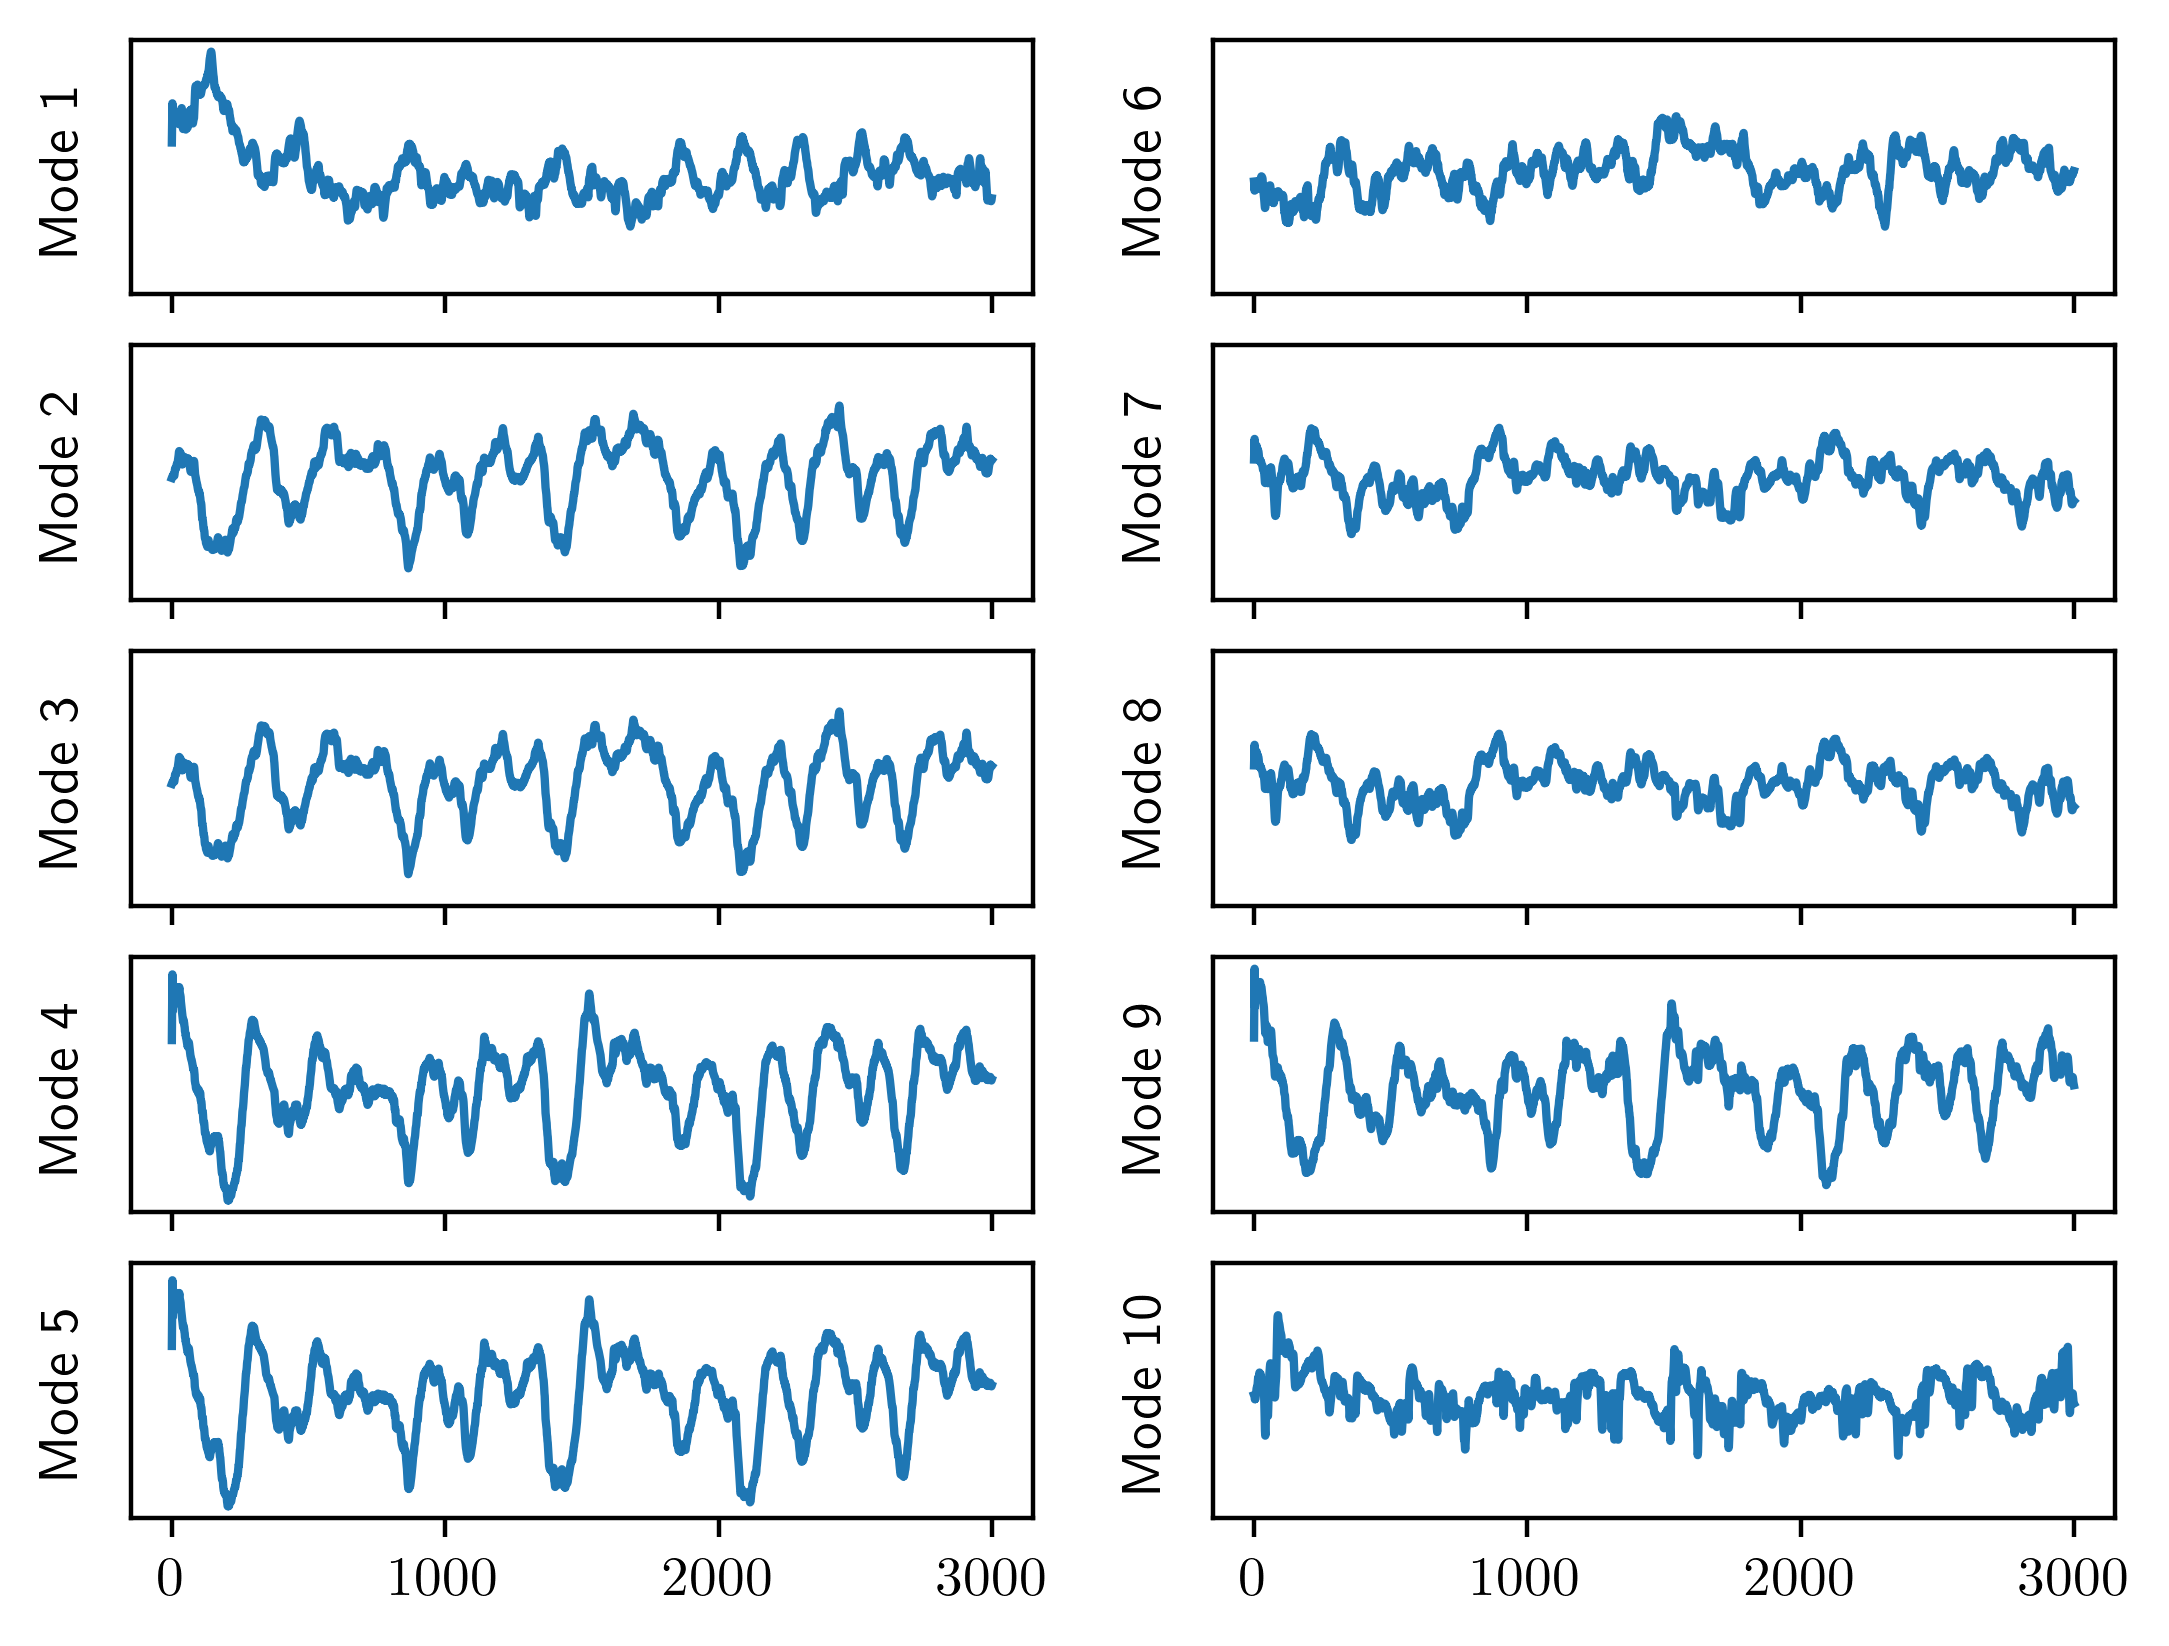

In [14]:
fig,ax = plt.subplots(5,2,sharex=True,sharey=True)
idx = np.argsort(np.abs(dmd_model.eigs))[::-1] # Get indices that sort eigenvalues in descending modulus order
proj = np.real(dmd_model.modes.T@V[:20,:3000]) # Project modes onto data and take real part
proj = proj[idx,:] # Sort by the indices we found earlier
for j in range(2):
    for i in range(5):
        ax[i,j].plot(proj[5*j+i])
        ax[i,j].set_yticks([])
        ax[i,j].set_ylabel("Mode " + str(5*j+i+1))

These modes are not really interpretable because the widefield temporal components are not easily interpretable. We can do better by multiplying back the rest of the SVD of the widefield data. The result is a 3000 frame $560\times 560$ pixel video. I have not done this for DMD yet because, as we can see below, there is some reason to believe that the DMD fit is very poor. Before that though, let's look at the frequencies of each DMD mode. The formula for the frequency of the mode associated with eigenvalue $\lambda_j$ (assuming $\lambda_j$ is a discrete-time eigenvalue) is
$$\text{freq}_j=\frac{\left|\text{Imag }\log(\lambda_j)\right|}{2\pi\Delta t},$$
where $\Delta t$ is the time between each of our timepoints, which is $0.0285s$ in our case.  We will sort the frequencies in order of decreasing amplitude (the coefficients $b_j$ in the above formula).

In [16]:
df = pd.DataFrame()
dt = 0.0285
dmd_freqs = np.abs(np.imag(np.log(dmd_model.eigs))) / (2*np.pi*dt)
dmd_amplitudes = np.abs(dmd_model.amplitudes)
idx = np.argsort(dmd_amplitudes)[::-1]
df['Frequencies'] = dmd_freqs[idx]
df['Amplitudes'] = dmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.000000    0.007346
1     0.000000    0.006971
2     0.141736    0.005788
3     0.141736    0.005788
4     0.106196    0.004004
5     0.106196    0.004004
6     0.000000    0.002682
7     0.000000    0.002407
8     0.061206    0.000872
9     0.061206    0.000872


We can see that a DMD fit with only ten modes finds only low frequency modes; the highest frequency mode completes only twelve periods during the entire 85.5s training window. Each of the modes comes in complex conjugate pairs because our data is real. It is surprising to me that we have two pairs of zero frequency modes (a single constant pair tends to be more common), and that our higher amplitude modes have higher frequencies. This may indicate that our DMD fit is not very good.

Let's plot the first ten components in the actual data and the reconstructed data.

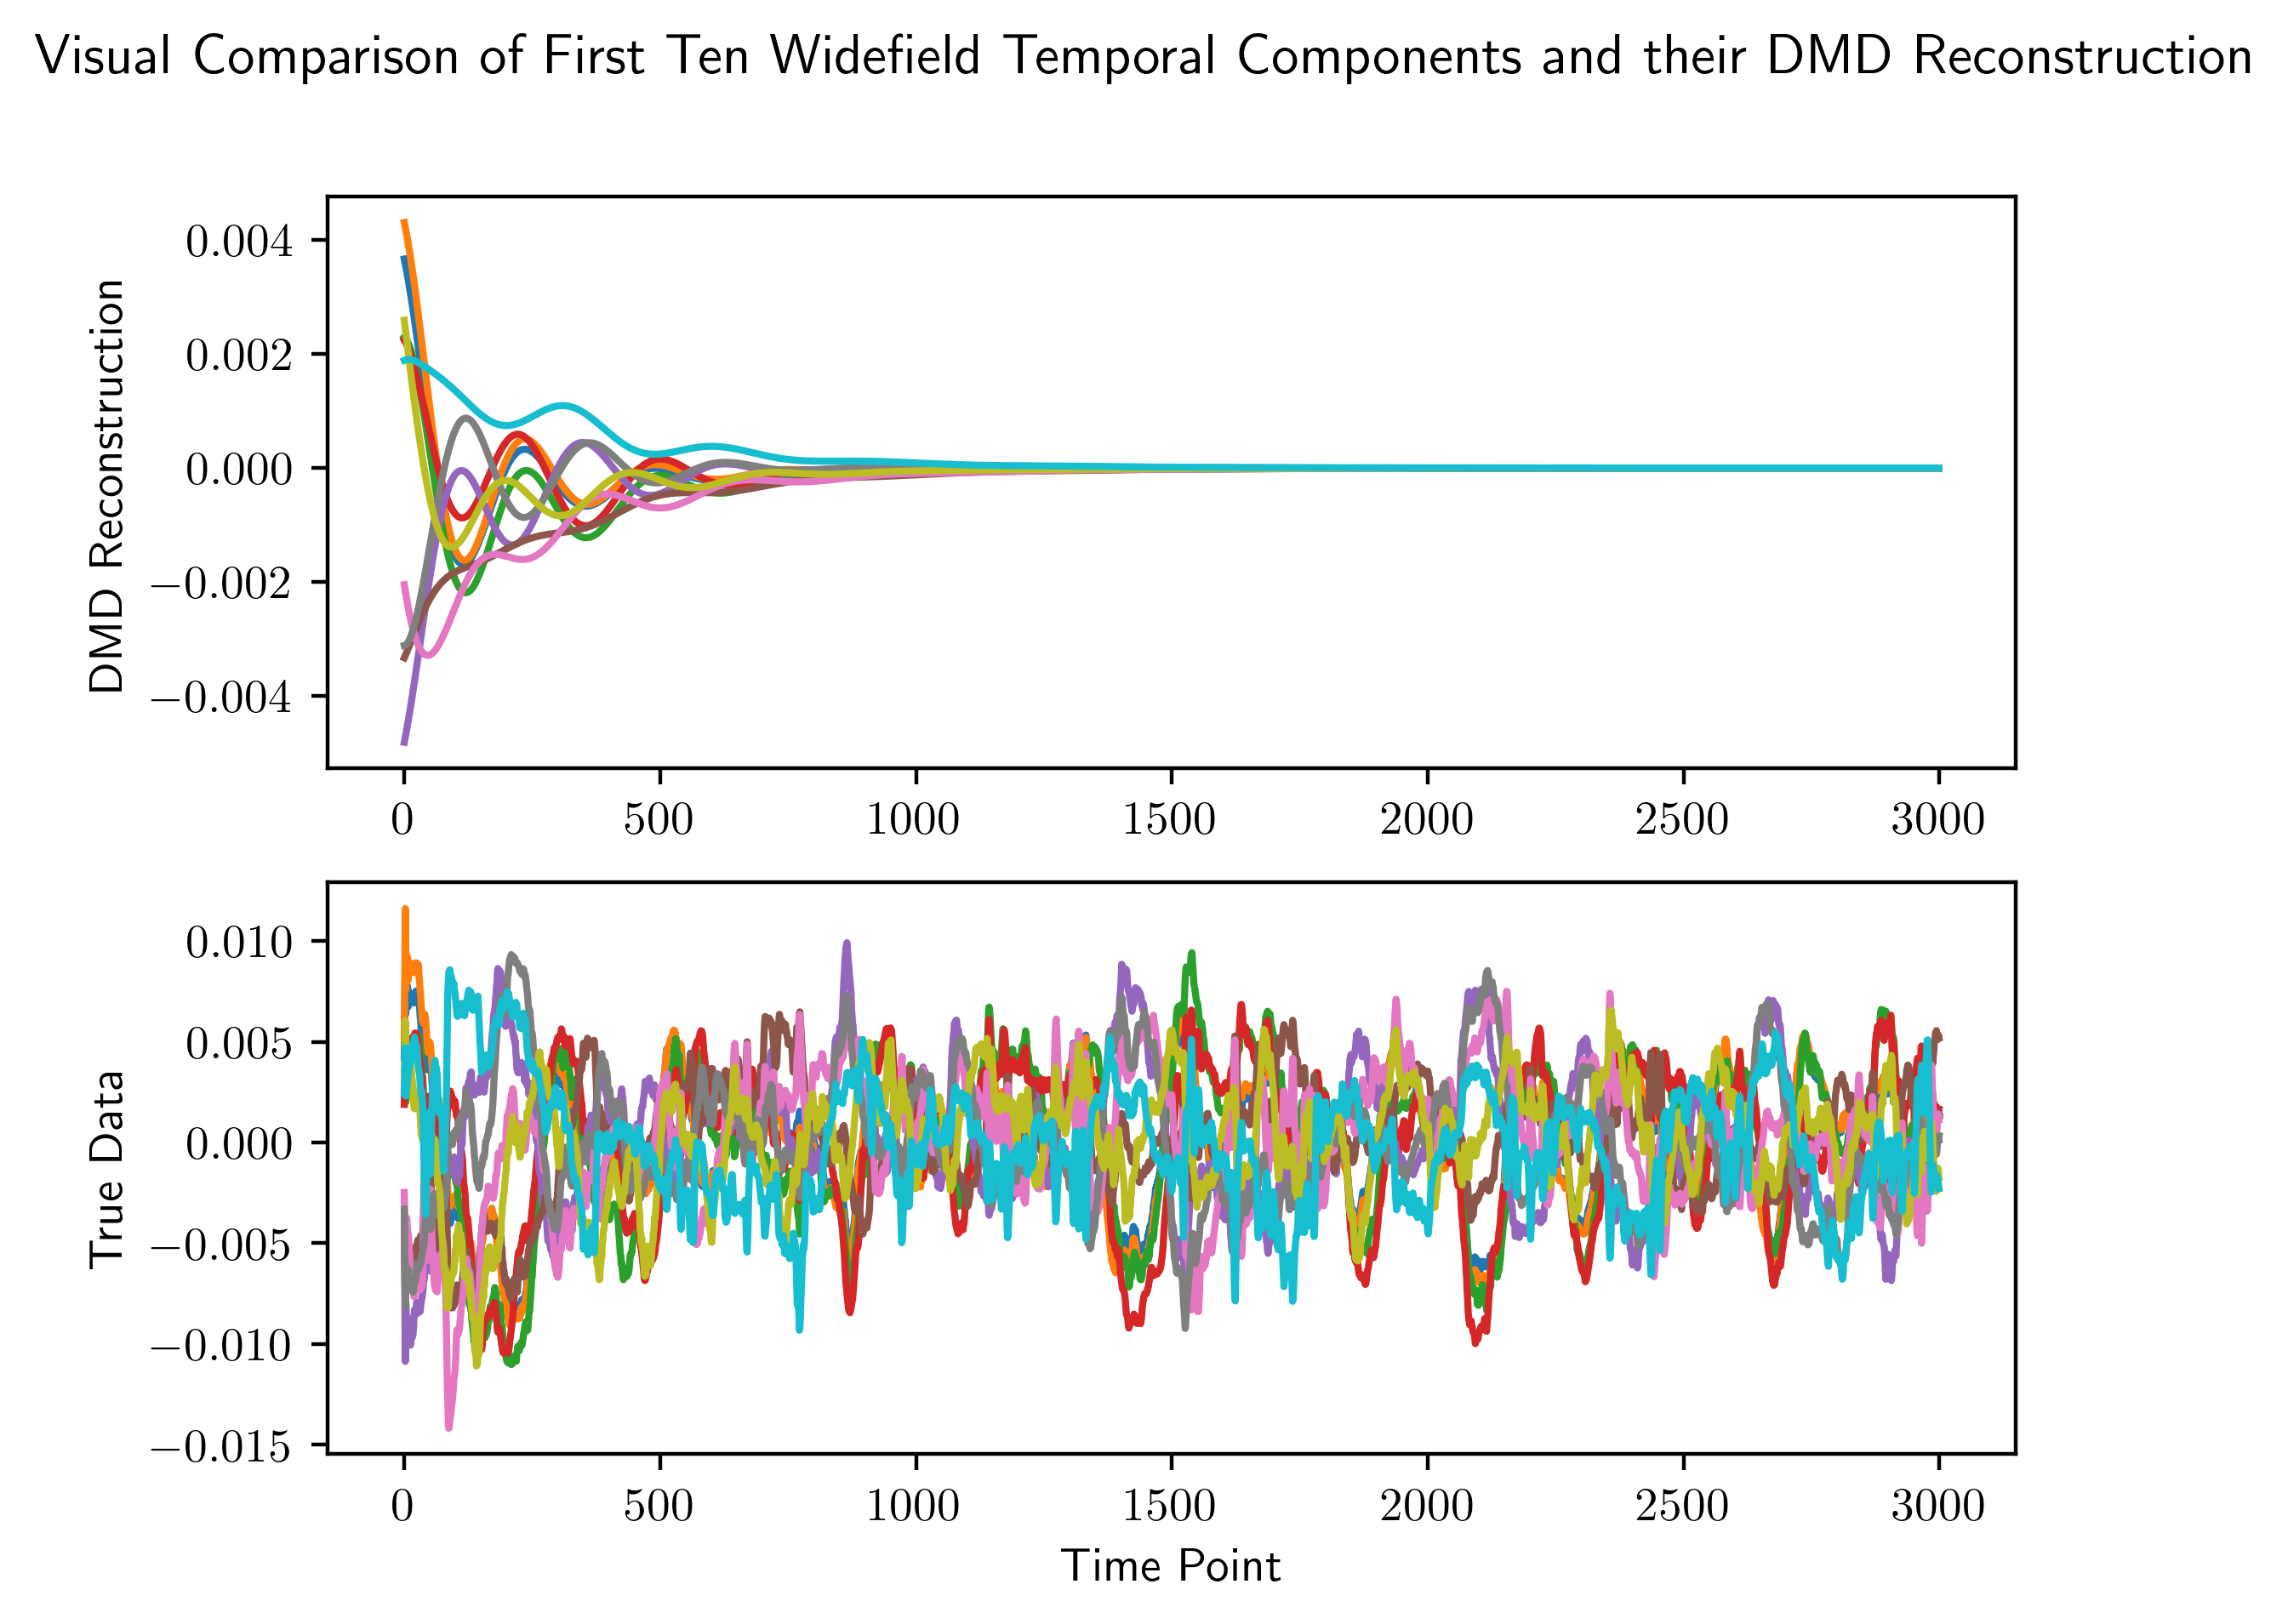

In [5]:
fig,ax = plt.subplots(2,1)
for i in range(10):
    ax[0].plot(np.real(dmd_model.reconstructed_data[i,:]))
    ax[0].set_ylabel("DMD Reconstruction")
    ax[1].plot(V[i,:3000])
    ax[1].set_ylabel("True Data")
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of First Ten Widefield Temporal Components and their DMD Reconstruction");

As we can see, the DMD reconstruction decays to zero almost immediately. This is unfortunately typical of DMD. We can quantify the error with the relative squared error:
$$\text{RSE}(X,Y)=\frac{\sum_{i=1}^n(Y_i-X_i)^2}{\sum_{i=1}^n(Y_i-\bar Y_i)^2},$$
where $X$ is our reconstruction (flattened out into a length n vector), $Y$ is the flattened out true data, and $\bar Y$ is the mean of $Y$. The numerator in this error term reflects the average deviation between the reconstruction and the data, while the denominator is a normalization term that accounts for the fact that the data values themselves are small on average. An interpretation for this error is as a measure of how good our model is at predicting our data at each time point compared to us just predicting that at each time point the data is equal to its mean value. With this interpretation, RSEs larger than $1$ indicate a worse predictor than simply guessing that the data equals its mean, while RSEs between $0$ and $1$ indicate that our model is better, with the amount that we are better by being one over the RSE.

In [3]:
RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

In [7]:
print("RSE for the DMD fit: " + str(RSE(dmd_model.reconstructed_data,V[:20,:3000])))

RSE for the DMD fit: 0.9494129770750516


So the DMD fit appears to be slightly better than just using the mean as our prediction. However, this is helped significantly by the fact that the mean is zero, so at later times using DMD and using the mean as our predictor are equivalent.

Fundamentally, the fit we achieve with DMD is optimal (in terms of one-step updates) in a least squares sense over the entire dataset that we fit, so that essentially we are assuming our data comes from a stationary process. This is an approximation that gets worse the longer the time series we use to fit is. Thus, we would expect a fit on a smaller amount of data to be better. Let's try 500 time points (14.25s) instead of 3000.

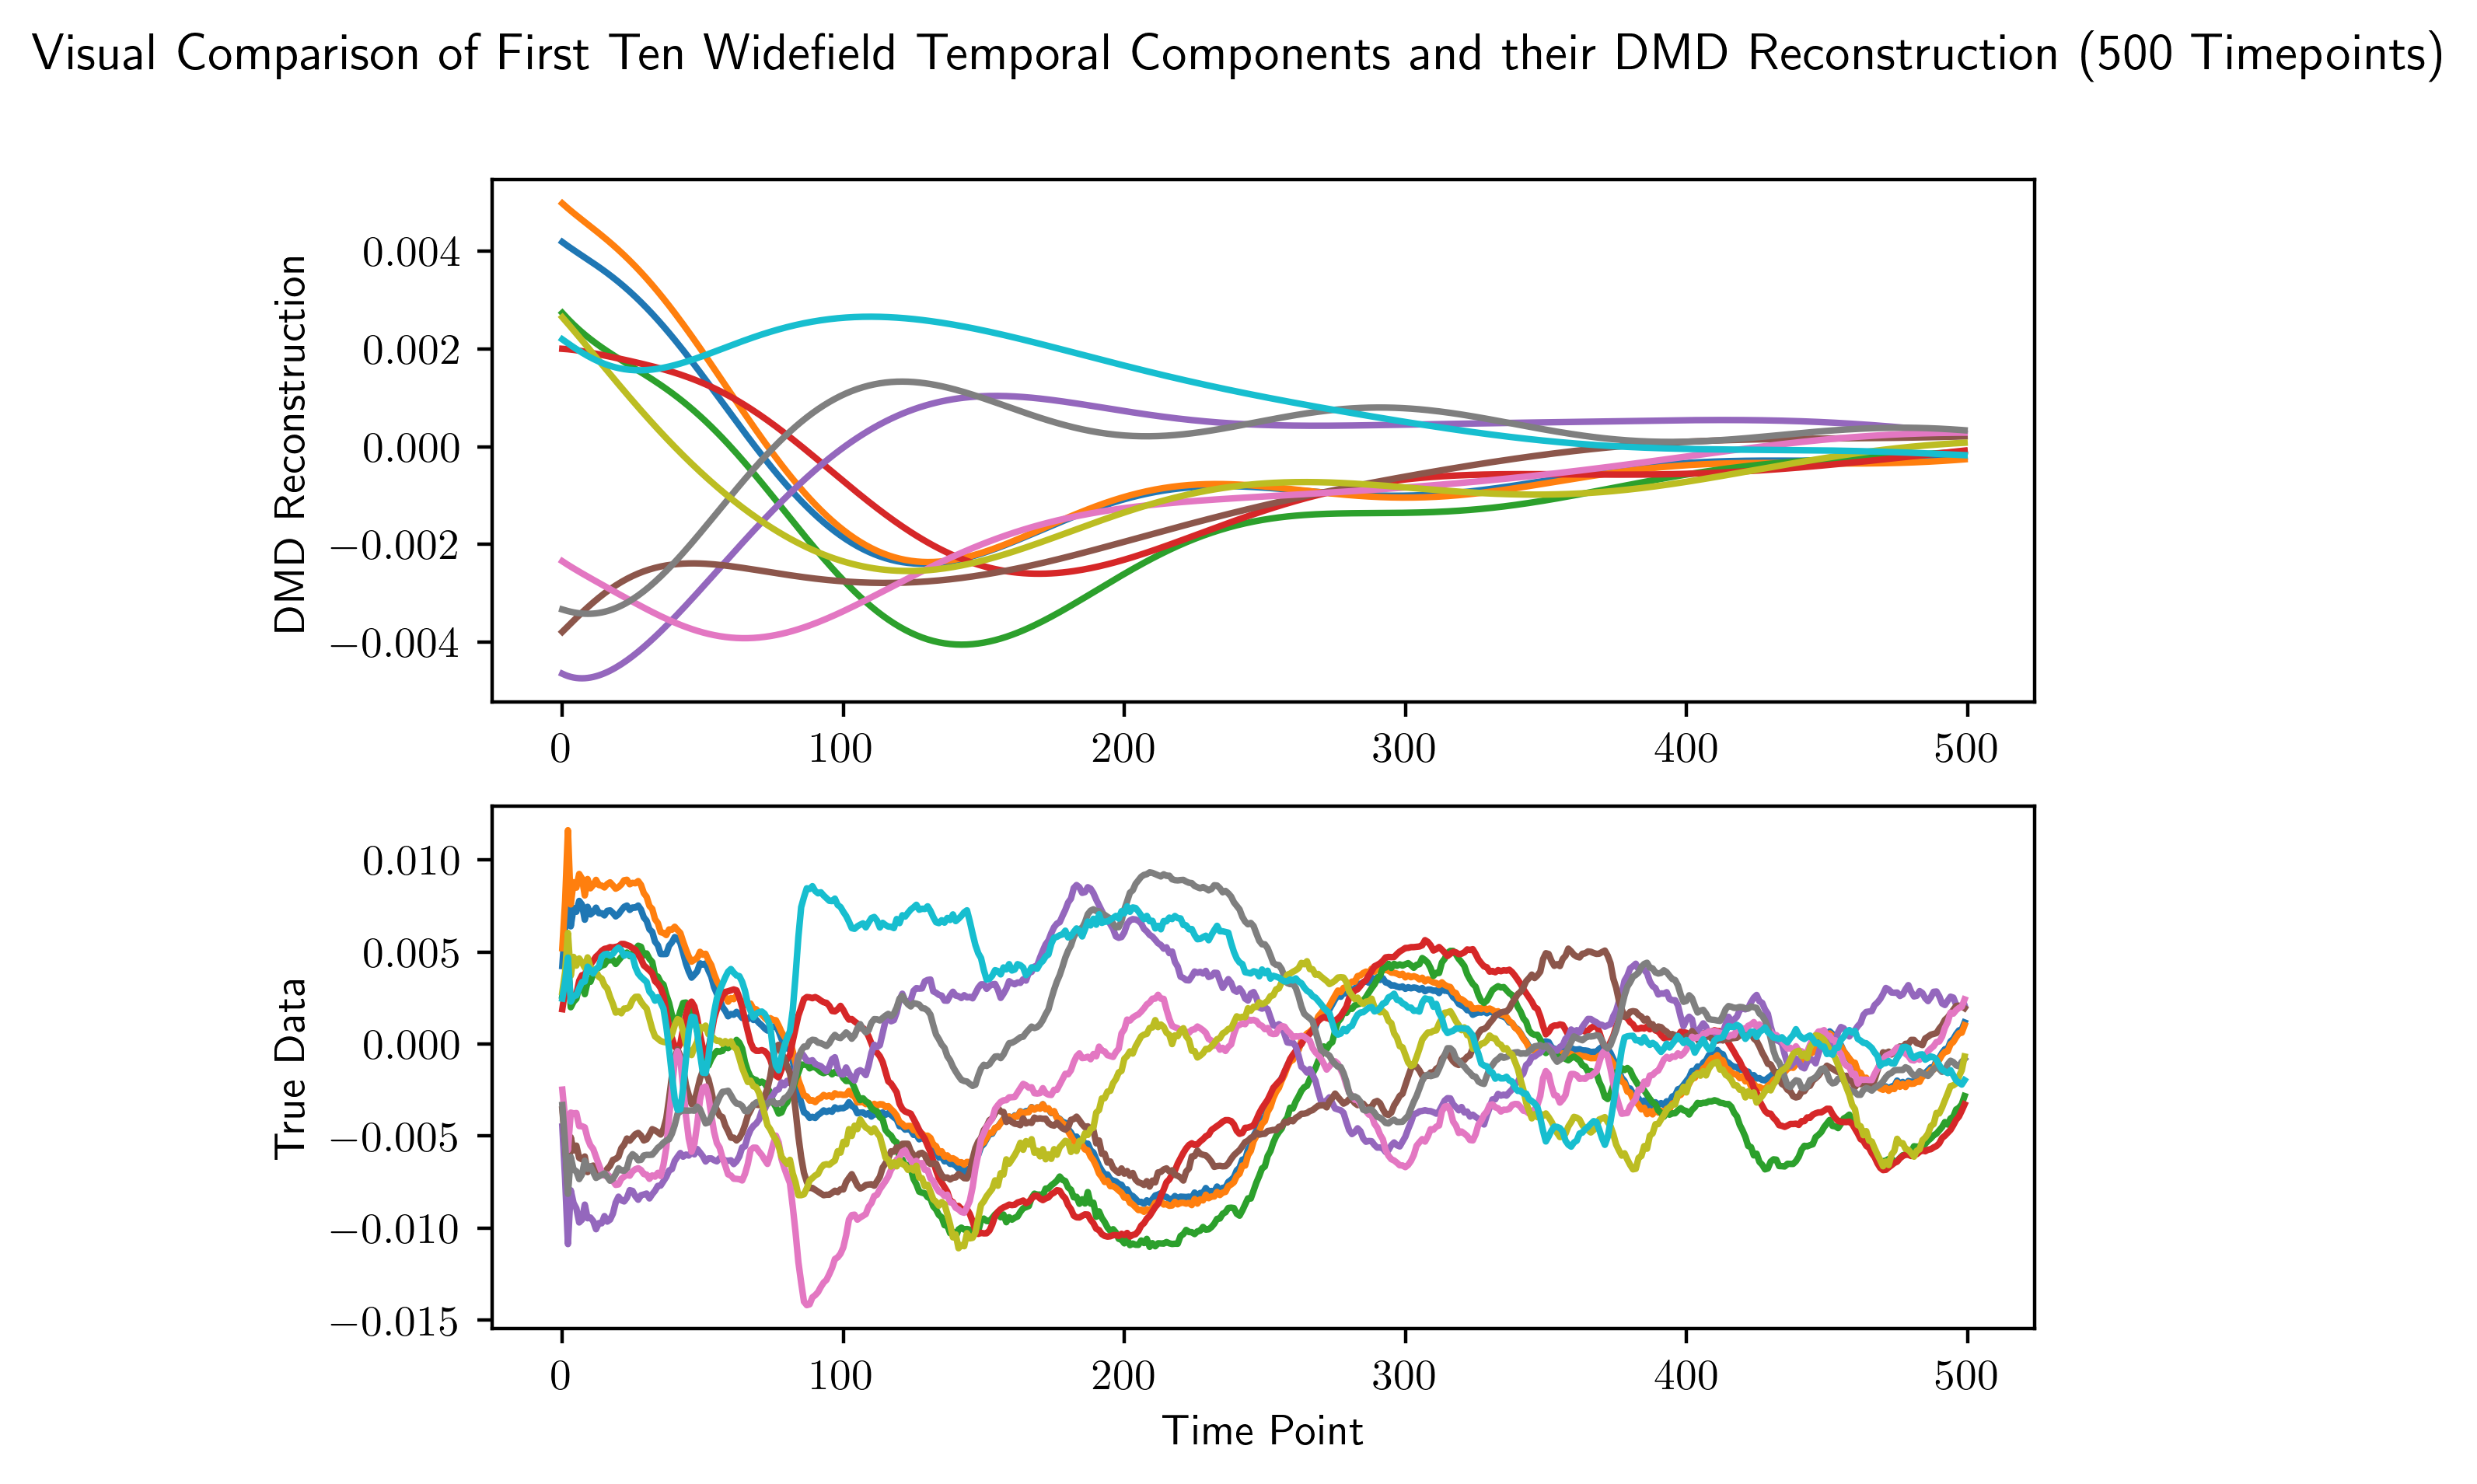

In [28]:
dmd_model_500_tp = DMD(svd_rank=10).fit(V[:20,:500])
fig,ax = plt.subplots(2,1)
for i in range(10):
    ax[0].plot(np.real(dmd_model_500_tp.reconstructed_data[i,:]))
    ax[0].set_ylabel("DMD Reconstruction")
    ax[1].plot(V[i,:500])
    ax[1].set_ylabel("True Data")
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of First Ten Widefield Temporal Components and their DMD Reconstruction (500 Timepoints)");

In [29]:
print("RSE for the DMD fit: " + str(RSE(dmd_model_500_tp.reconstructed_data,V[:20,:500])))

RSE for the DMD fit: 0.6481591611627949


Let's look at the frequencies in this case.

In [30]:
df = pd.DataFrame()
dt = 0.0285
dmd_freqs = np.abs(np.imag(np.log(dmd_model_500_tp.eigs))) / (2*np.pi*dt)
dmd_amplitudes = np.abs(dmd_model_500_tp.amplitudes)
idx = np.argsort(dmd_amplitudes)[::-1]
df['Frequencies'] = dmd_freqs[idx]
df['Amplitudes'] = dmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.033918    0.008213
1     0.033918    0.008213
2     0.000000    0.005390
3     0.000000    0.004184
4     0.137458    0.003739
5     0.137458    0.003739
6     0.177141    0.003087
7     0.177141    0.003087
8     0.248802    0.001781
9     0.248802    0.001781


The frequencies found in this case are higher than the frequencies found in the 3000 time point case. This is typical of fitting DMD to a smaller window of data.

DMD does better when there is less data to fit, but the fit is still poor. Thankfully, we can do much better.

OptDMD is a variation of DMD that does better by bypassing the discrete update matrix entirely, and instead solving

$$\min \|X-\Phi(\lambda)B\|_F\quad\text{over}\quad \lambda\in\mathbb{C}^k, B\in\mathbb{C}^{l\times n},$$
where $X\in\mathbb{C}^{m\times n},\Phi(\lambda)\in \mathbb{C}^{m\times l},$ and $\Phi(\lambda)_{i,j}=\exp(\lambda_jt_i)$.

What this means is that rather than finding the optimal update matrix, we find the optimal $b_j,\phi_j,$ and $\lambda_j$ such that the reconstruction
$$x_i\approx\sum_{j=1}^r b_j\phi_j e^{\lambda_jt_i}$$
is as good as possible. This algorithm is clearly solving the same problem as DMD, but does it in a much more effective way.

The problem is that finding these optimal parameters requires an iterative scheme that may converge to local minima, or not at all. This problem is mitigated somewhat by bagging (bootstrap aggregating).

The idea with bagging is to sample a subset of our data with replacement (bootstrapping), producing $k$ independent data sets. On each data set we fit the OptDMD model, giving us a distribution for each of the parameters. We take the mean of each distribution to be our final best estimate.

**Note**: I have realized recently that there is a problem with BopDMD implementation in the pyDMD package. It appears there is no check for whether the fit was any good. With bagging, it is possible for us to select a sample that is very unrepresentative of our actual data. With even one bad sample, our fit will be very poor. This problem is demonstrated below.

In [39]:
optdmd = BOPDMD(svd_rank=15,num_trials=0) # PyDMD's BOPDMD will use OptDMD if num_trials = 0
optdmd.fit(V[:20,:500],np.arange(500))
print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data,V[:20,:500])))
for i in range(10):
    bopdmd = BOPDMD(svd_rank=15,num_trials=20,trial_size=0.9999)
    bopdmd.fit(V[:20,:500],np.arange(500))
    print("(" + str(i+1) + "): BopDMD RSE: " + str(RSE(bopdmd.reconstructed_data,V[:20,:500])))

OptDMD RSE: 0.04439817200727542
(1): BopDMD RSE: 0.04433932227265159
(2): BopDMD RSE: 0.04434090088454961
(3): BopDMD RSE: 0.0443455210797183
(4): BopDMD RSE: 0.04434322360868775
(5): BopDMD RSE: 0.0444098976052164
(6): BopDMD RSE: 0.044339873194365866
(7): BopDMD RSE: 0.044338184049829484
(8): BopDMD RSE: 0.04433863632498539
(9): BopDMD RSE: 0.04434114692316096
(10): BopDMD RSE: 0.04433665925363501


Unfortunately in no cases here did BOPDMD outperform OptDMD (on other trials it sometimes did). Note: This does not occur when the svd rank equals 10, but with higher SVD ranks the BOPDMD implementation appears to become less and less stable. As a consequence I will just use OptDMD here.

Let's use OptDMD to determine the dimensionality of the first 1000 timepoints of our data. (I fit only to the first 100 temporal components here for speed/memory reasons. This is probably not a bad approximation of the full temporal data based on the PCA results).

In [11]:
RSEs = np.zeros(50)
for i in tqdm(range(50)):
    optdmd = BOPDMD(svd_rank=i+1,num_trials=0)
    optdmd.fit(V[:50,:1000],np.arange(1000))
    RSEs[i] = RSE(optdmd.reconstructed_data,V[:50,:1000])

100%|███████████████████████████████████████████| 50/50 [00:42<00:00,  1.16it/s]


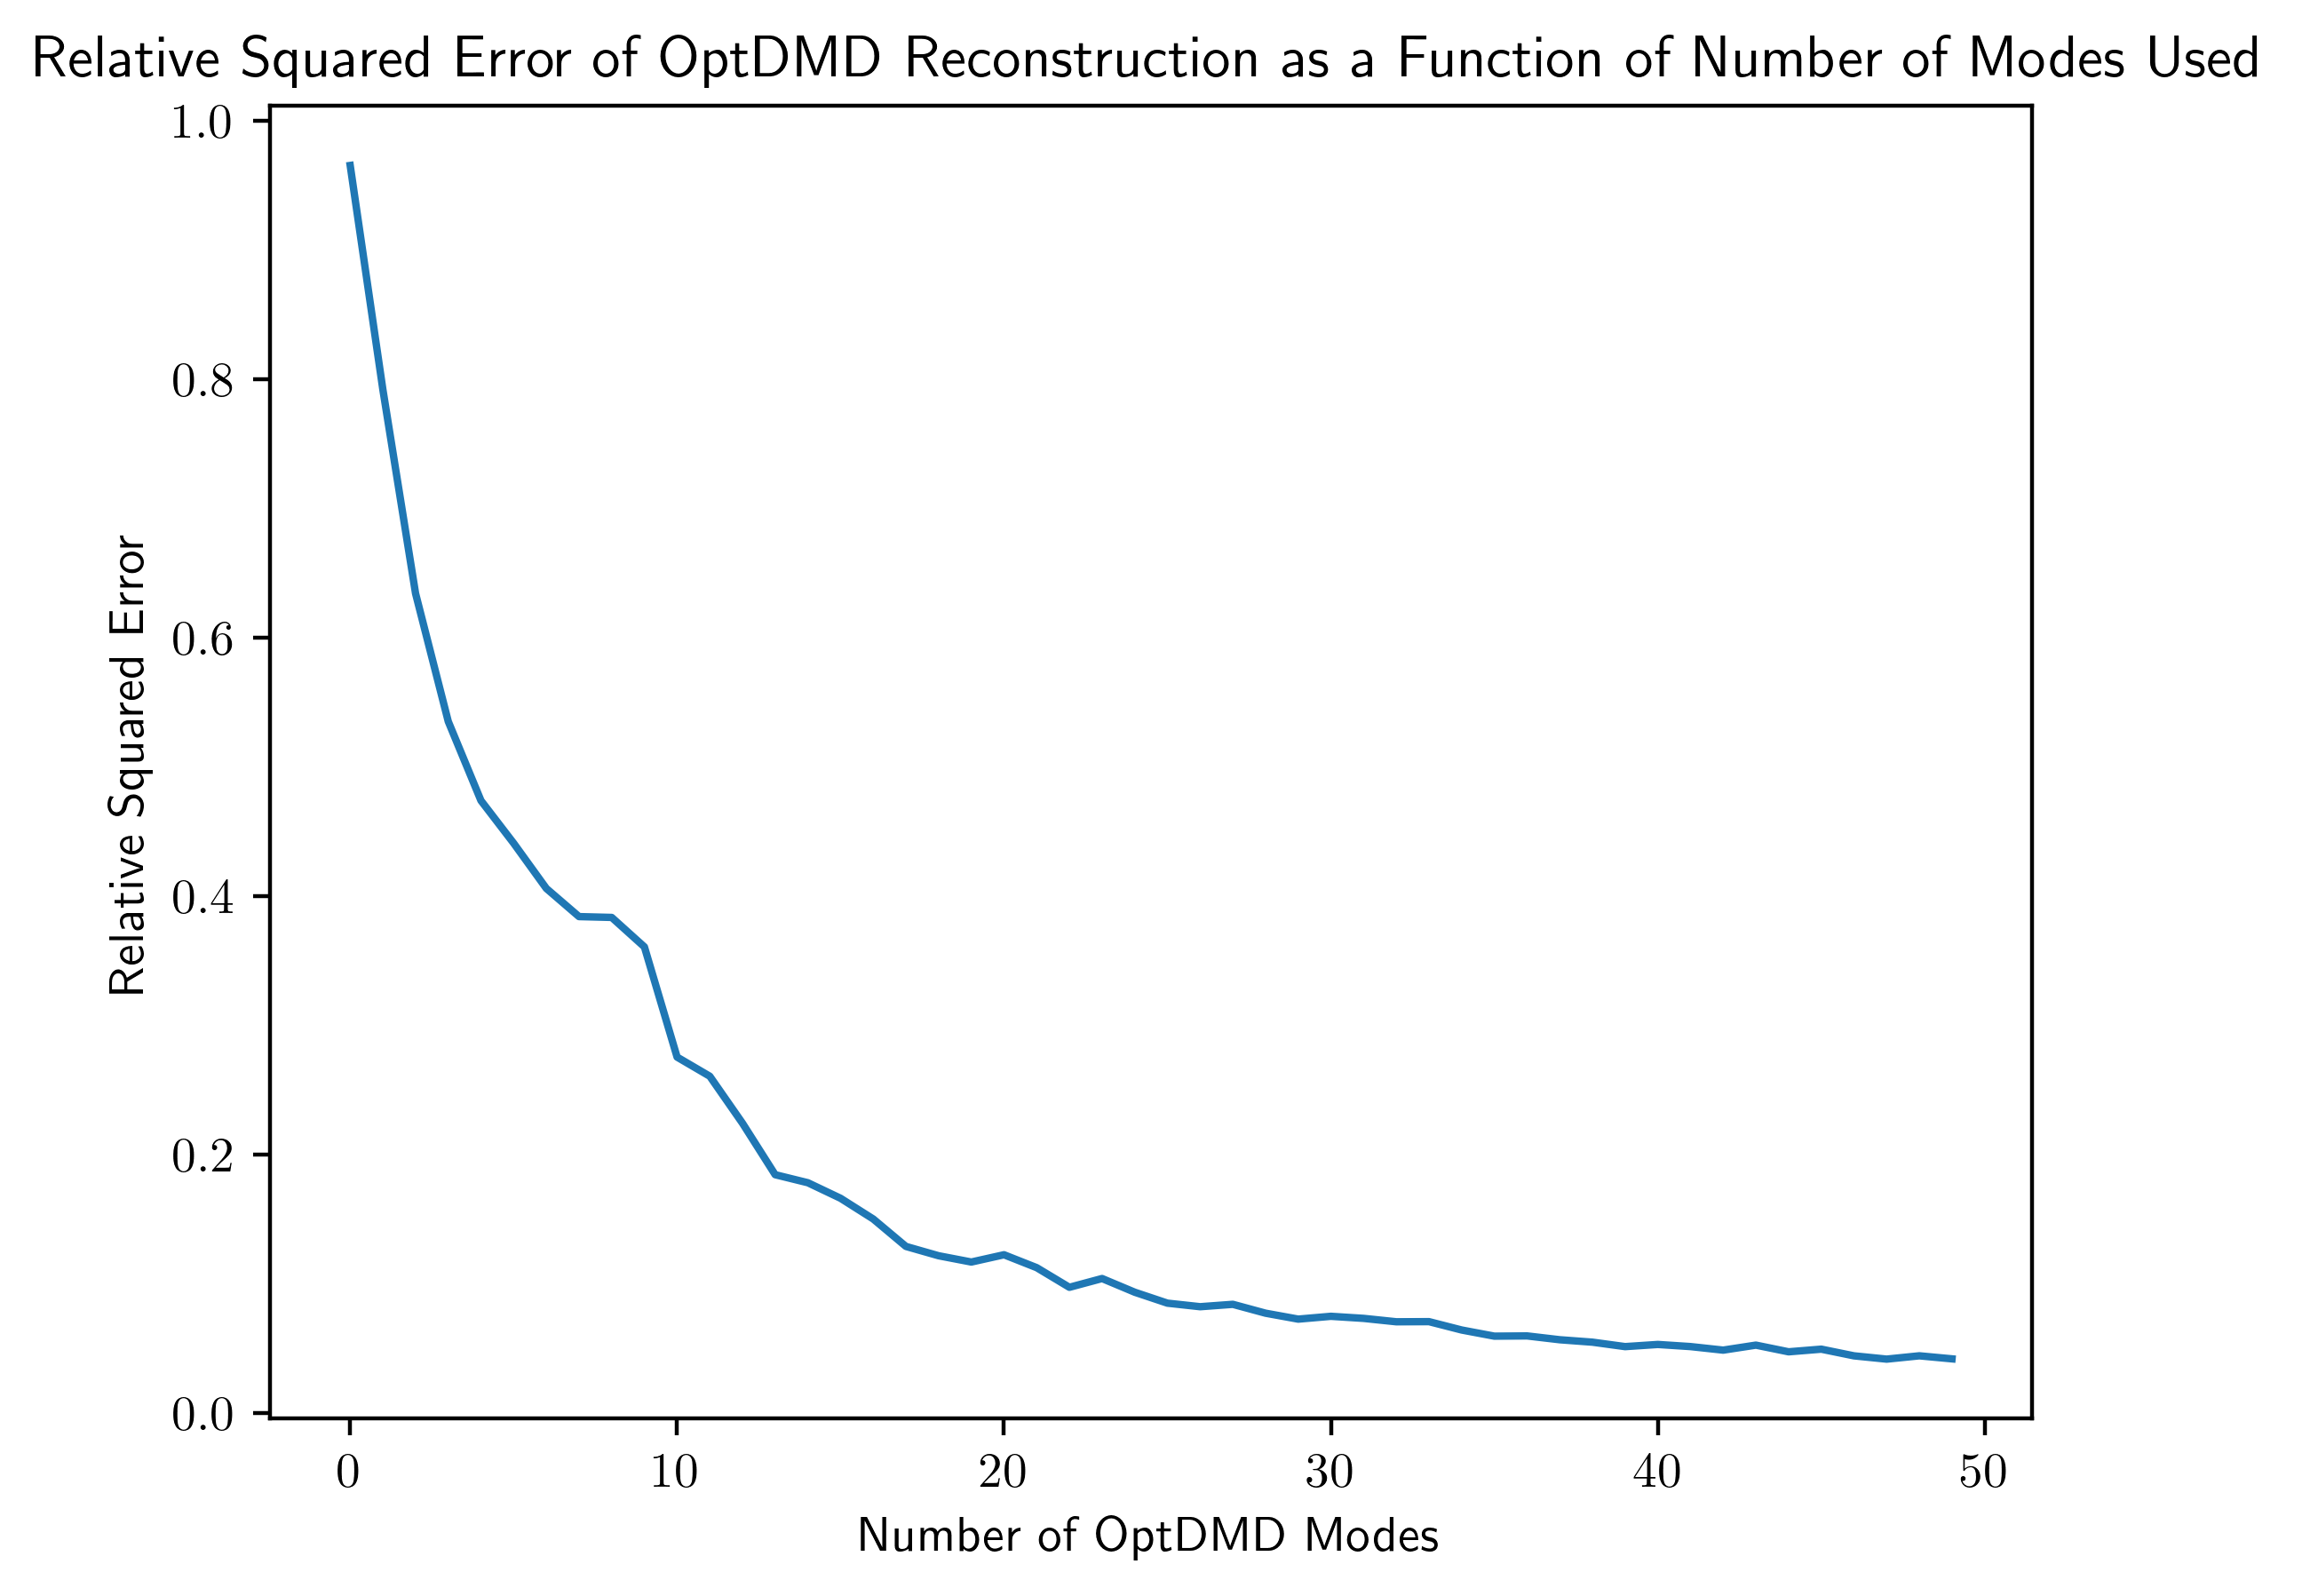

In [12]:
plt.plot(RSEs)
plt.xlabel("Number of OptDMD Modes")
plt.ylabel("Relative Squared Error")
plt.title("Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used");

About 12 components appears reasonable, although it is clear that the biggest performance gains come from the first 8-9. Let's stick with 12 and plot the results.

Text(0.5, 0.98, 'Visual Comparison of OptDMD Reconstruction and True Data')

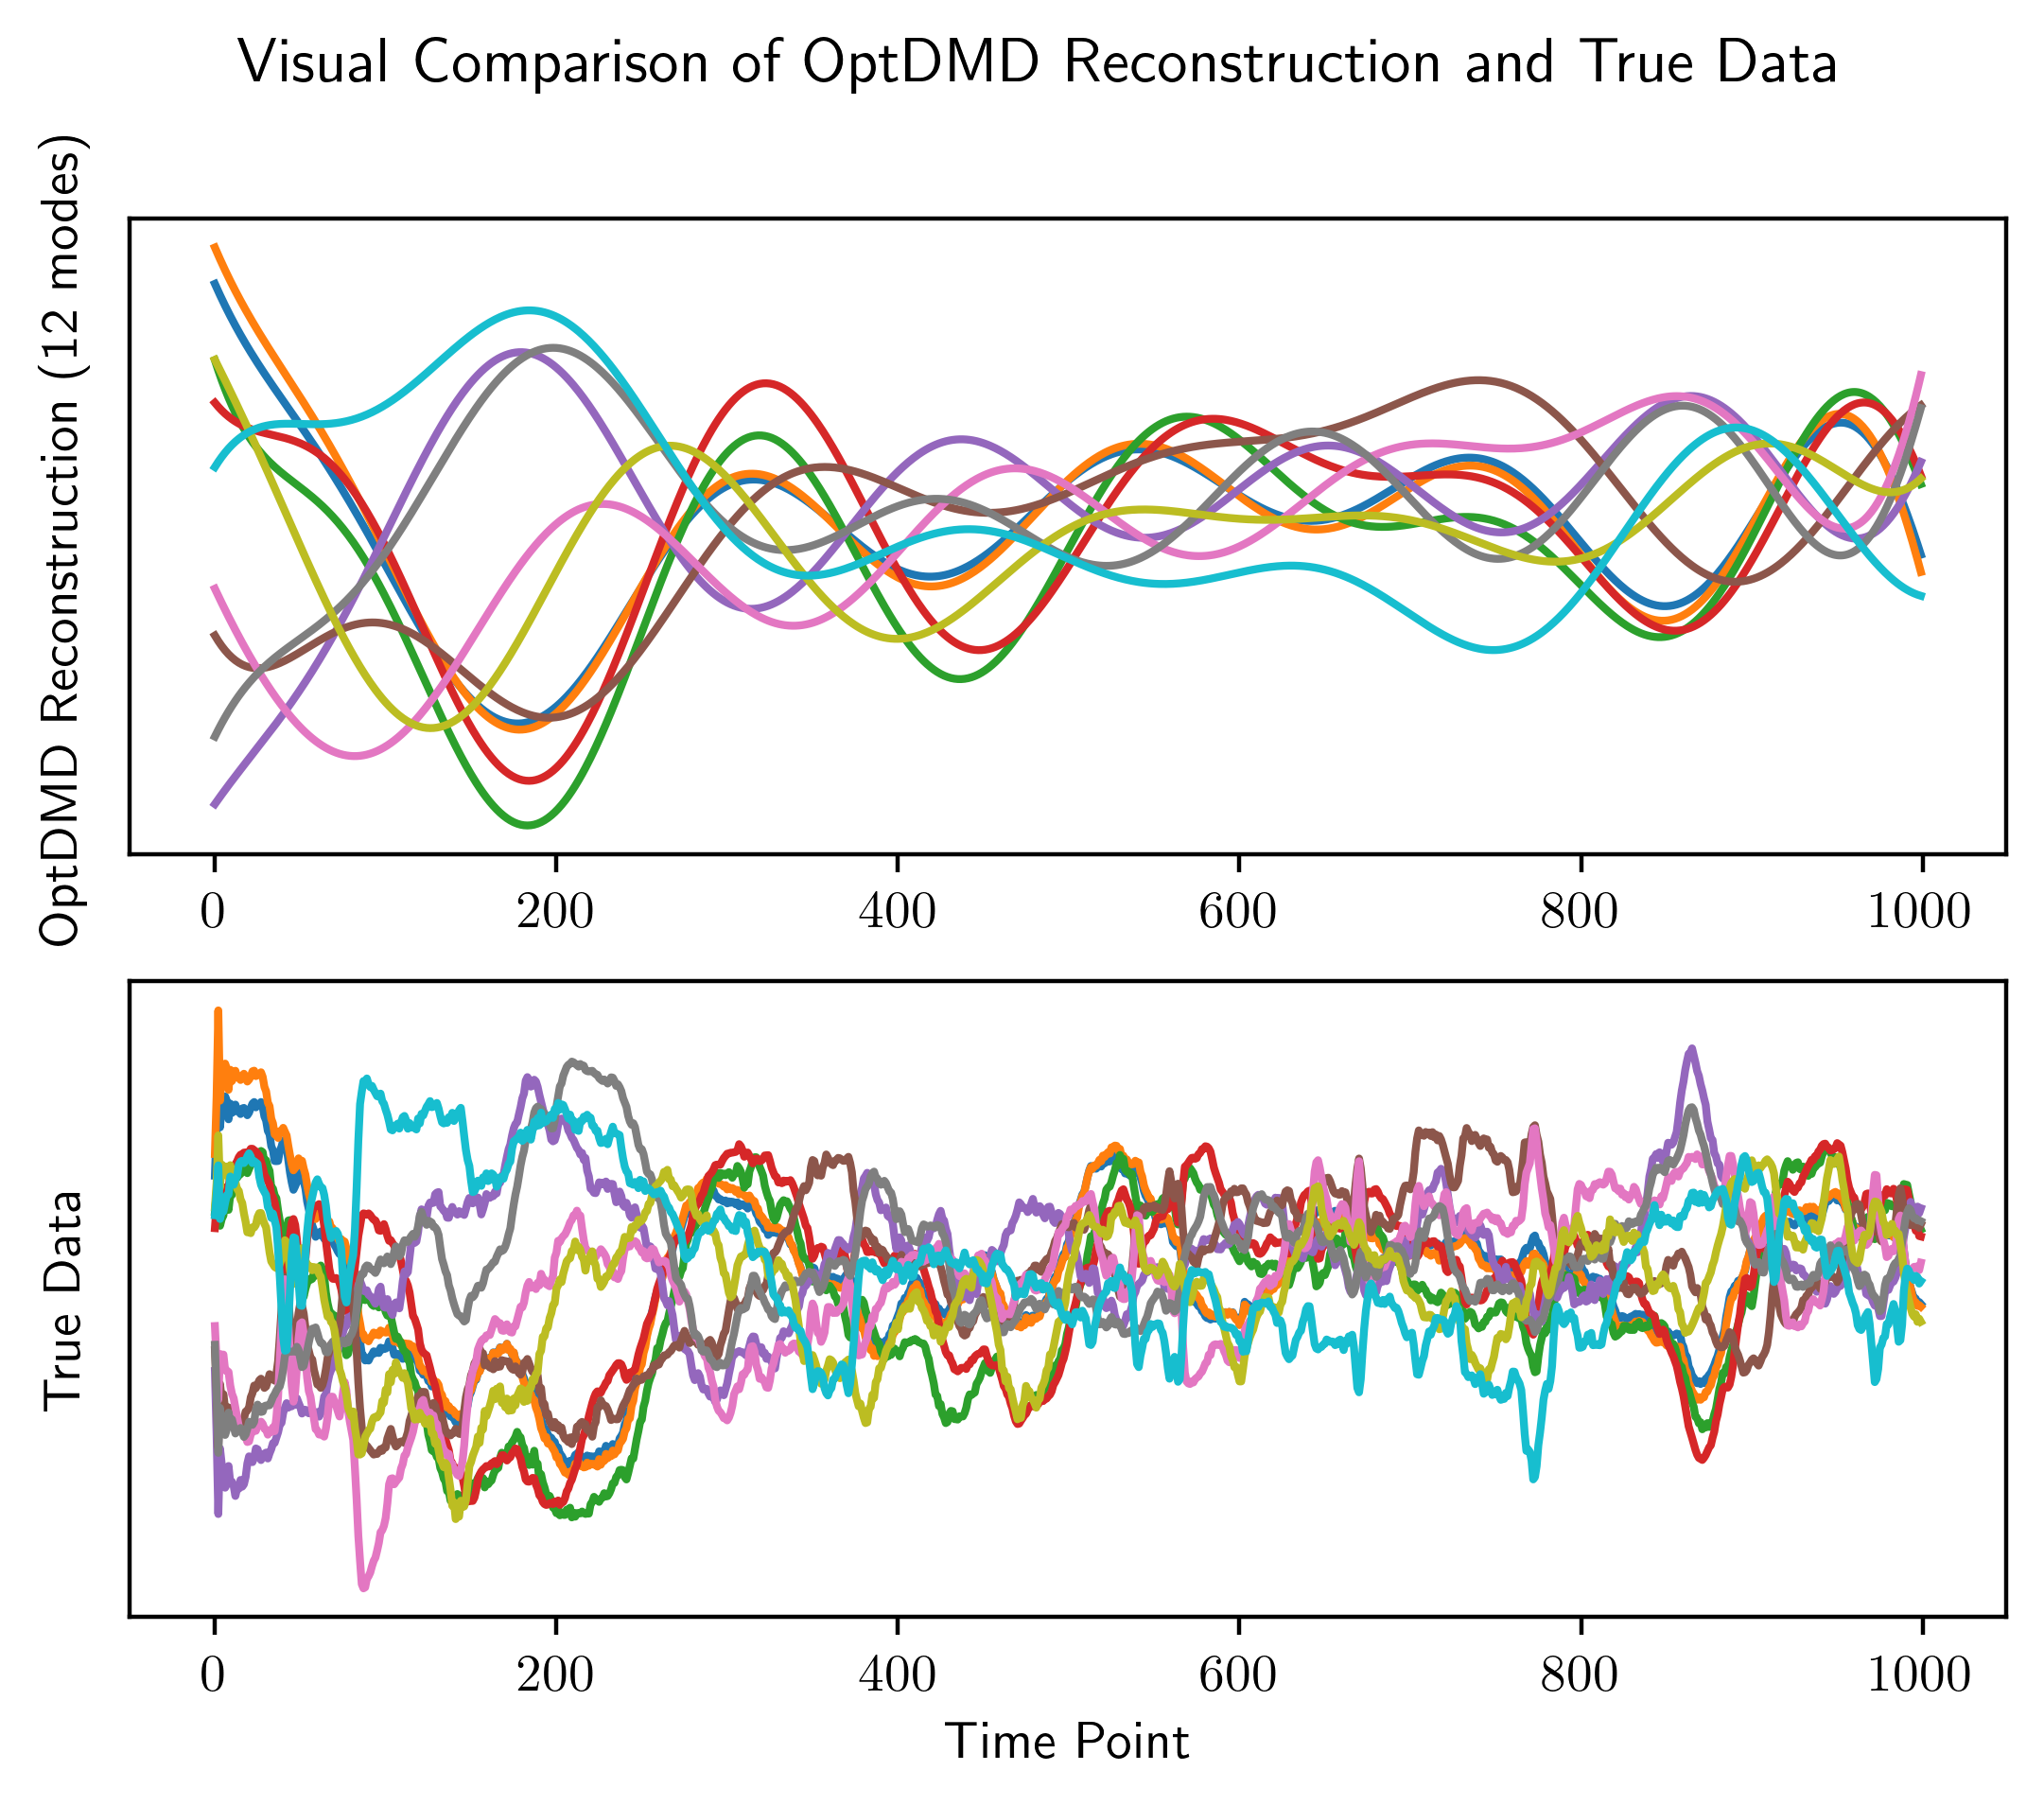

In [13]:
fig,ax = plt.subplots(2,1)
optdmd = BOPDMD(svd_rank=12,num_trials=0)
optdmd.fit(V[:50,:1000],np.arange(1000))
for i in range(10):
    ax[0].plot(np.real(optdmd.reconstructed_data[i,:]))
    ax[0].set_ylabel("OptDMD Reconstruction (12 modes)")
    ax[0].set_yticks([])
    ax[1].plot(np.real(V[i,:1000]))
    ax[1].set_ylabel("True Data")
    ax[1].set_yticks([])
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of OptDMD Reconstruction and True Data");

The fit is clearly much better than in the DMD case. We can do even better on a smaller timescale. Let's find the optimal rank for the first 500 time points.

In [22]:
RSEs = np.zeros(50)
for i in tqdm(range(50)):
    optdmd = BOPDMD(svd_rank=i+1,num_trials=0)
    optdmd.fit(V[:50,:500],np.arange(500))
    RSEs[i] = RSE(optdmd.reconstructed_data,V[:50,:500])

100%|███████████████████████████████████████████| 50/50 [00:27<00:00,  1.82it/s]


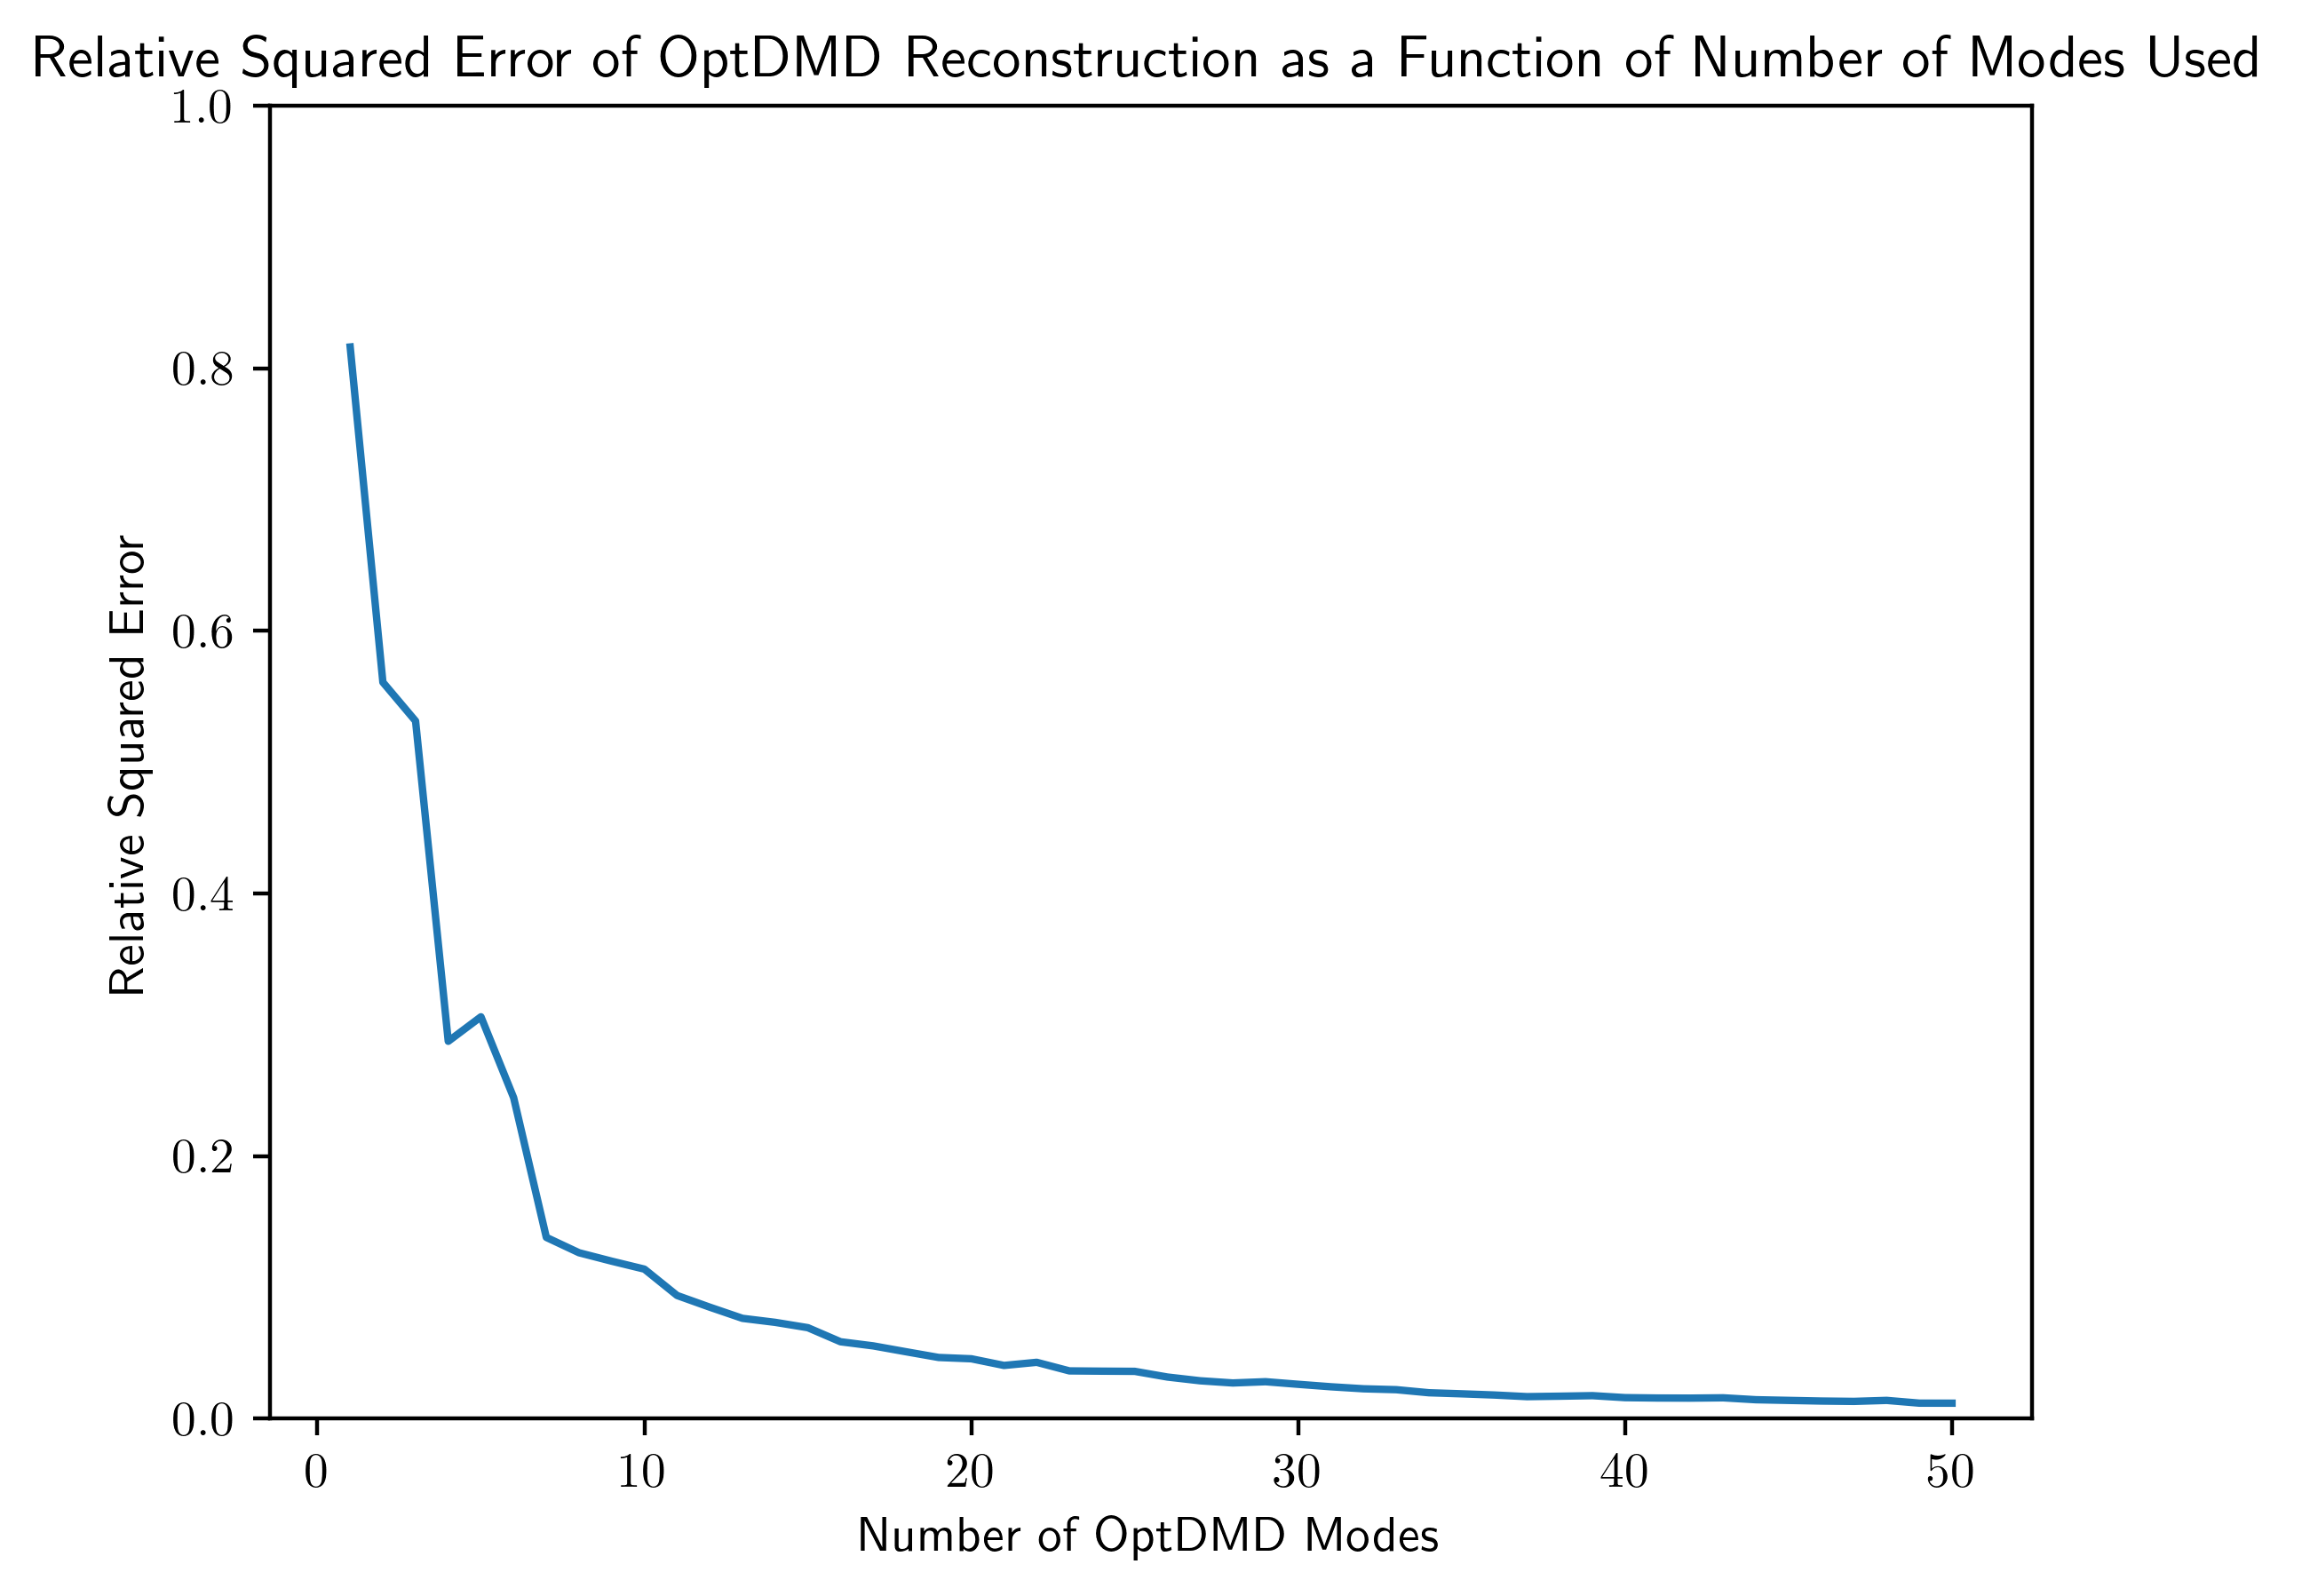

In [23]:
plt.plot(np.arange(1,51),RSEs)
plt.xlabel("Number of OptDMD Modes")
plt.ylabel("Relative Squared Error")
plt.title("Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used")
plt.ylim(0,1);

Let's plot this on a log scale as well.

Text(0.5, 1.0, 'Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used')

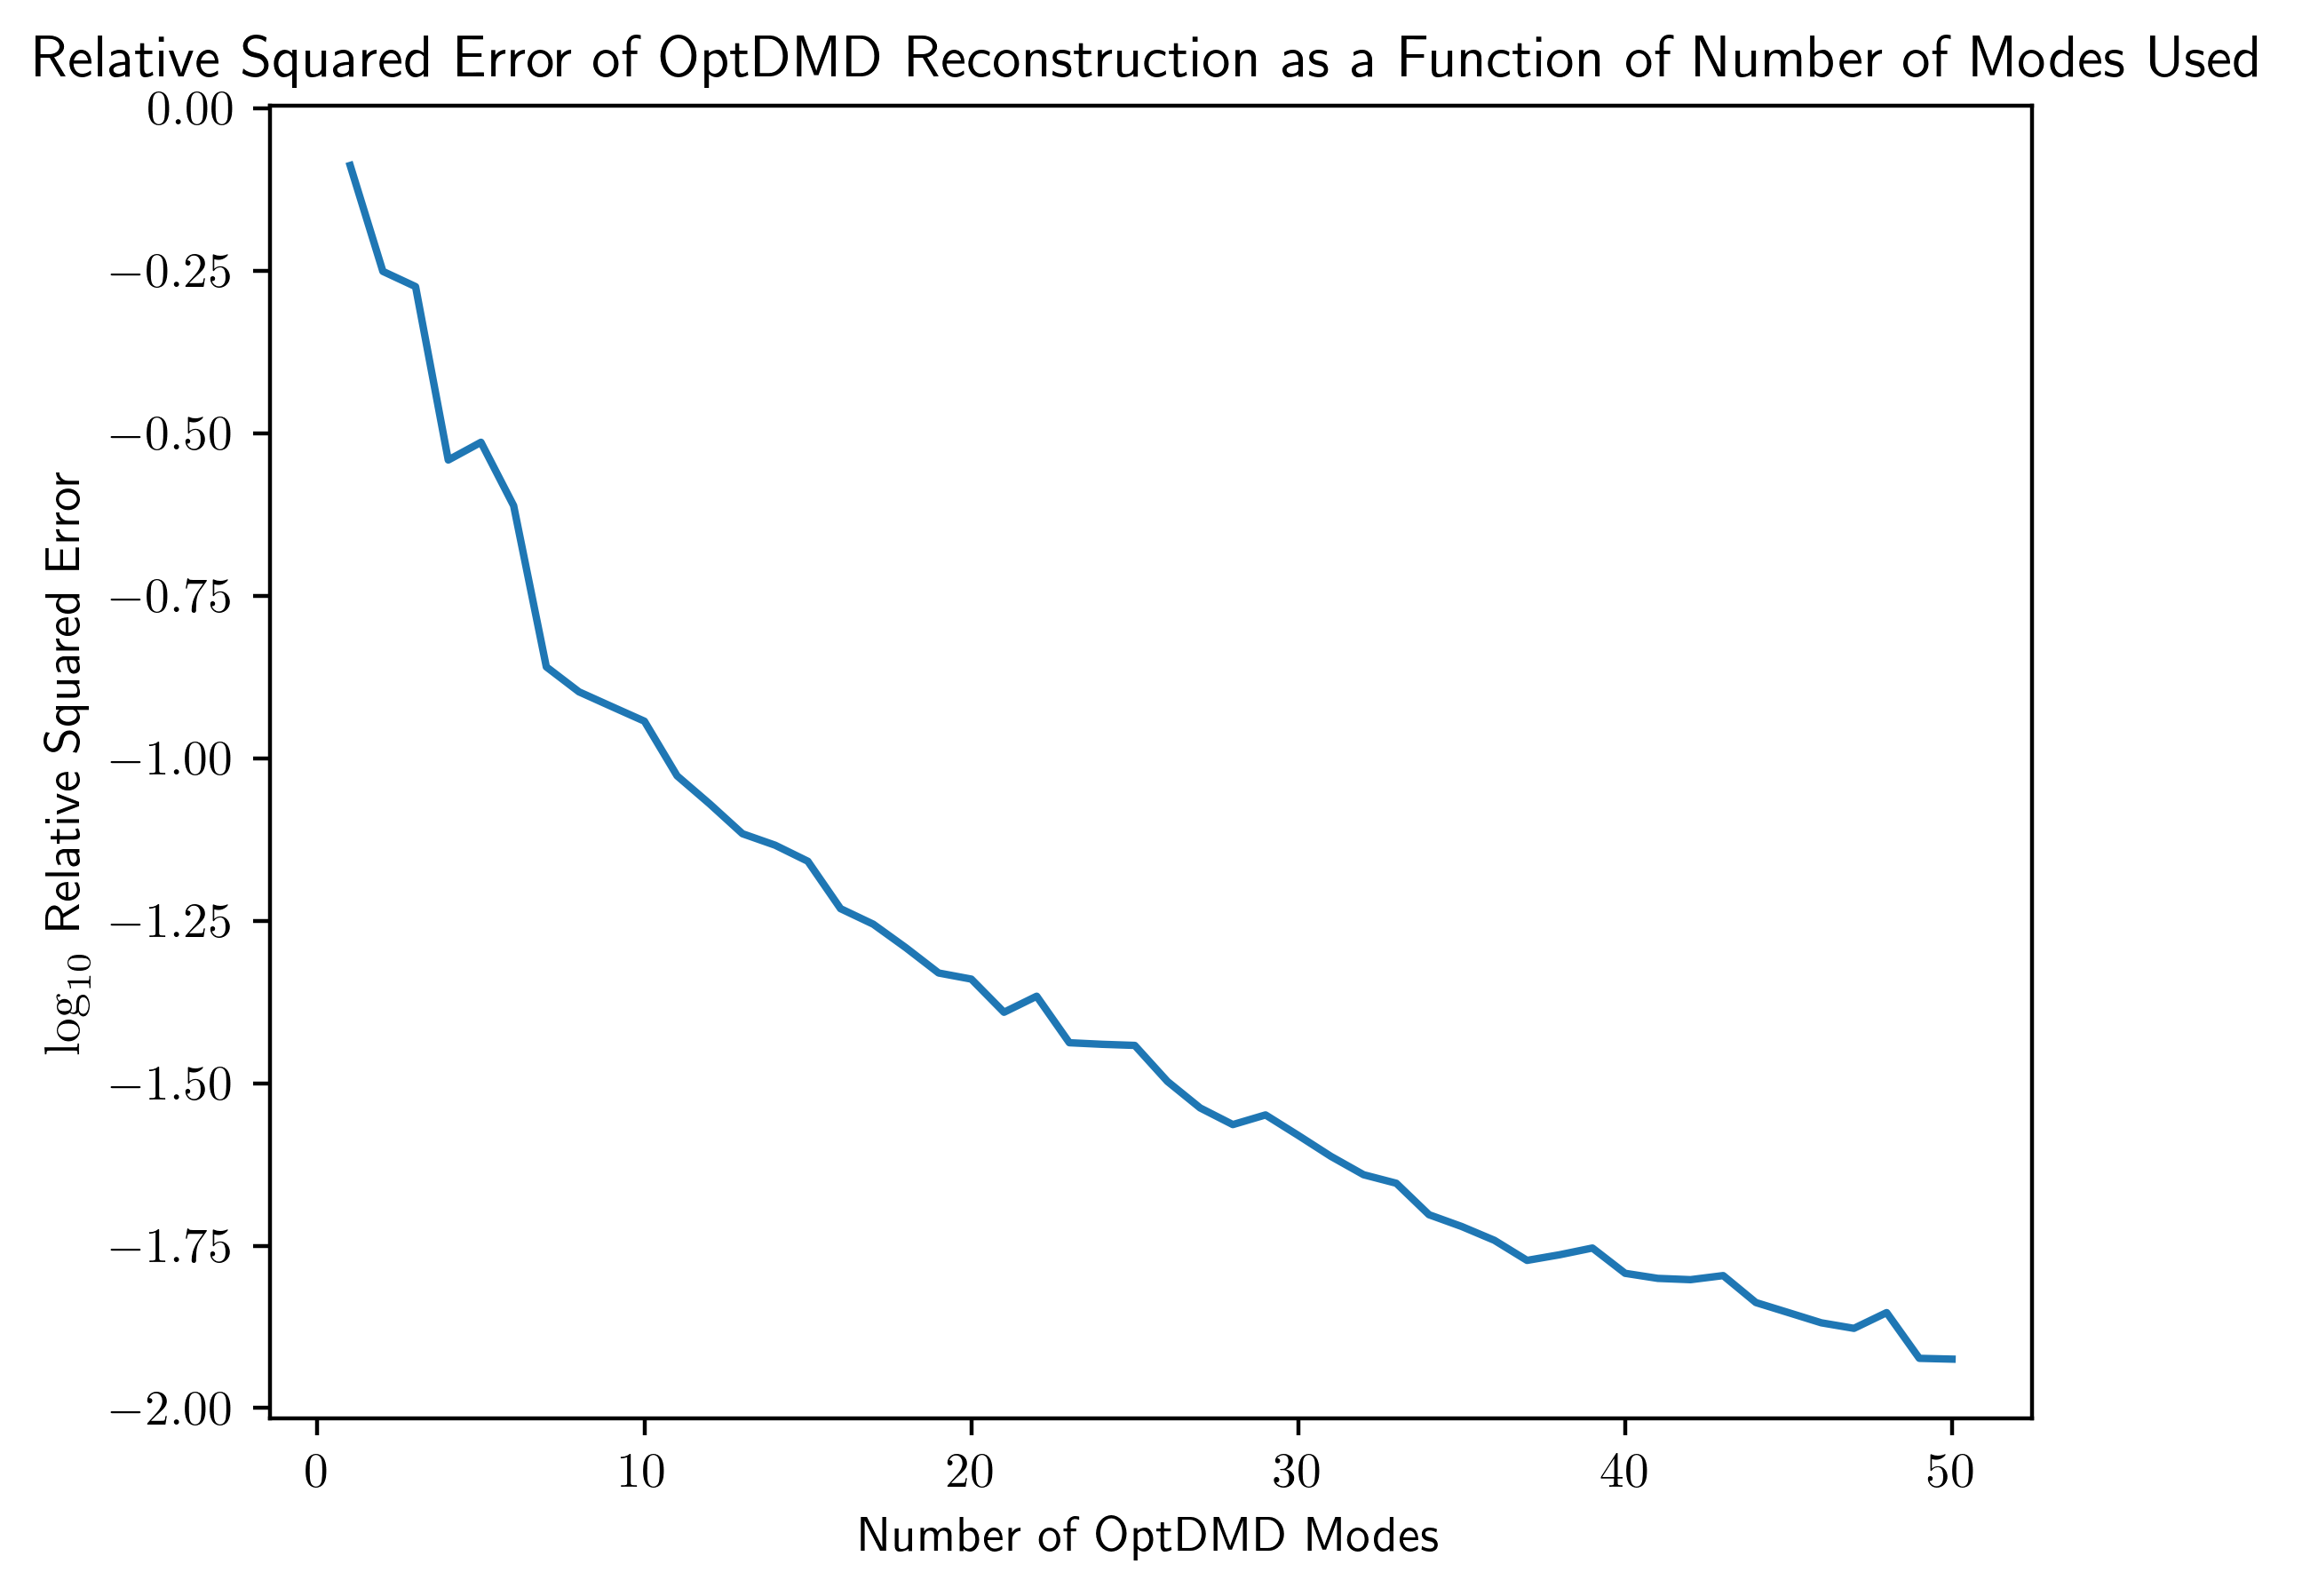

In [26]:
plt.plot(np.arange(1,51),np.log10(RSEs))
plt.xlabel("Number of OptDMD Modes")
plt.ylabel("$\log_{10}$ Relative Squared Error")
plt.title("Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used")

Components 0-10 seem to be where the rate of error shrinkage is greatest, although the error still decreases exponentially as a function of the number of OptDMD modes (as it is linear on the log scale). Let's plot the 10 mode and 50 mode reconstructions.

Text(0.5, 1.01, 'Reconstructions of Widefield Temporal Components with OptDMD Fits')

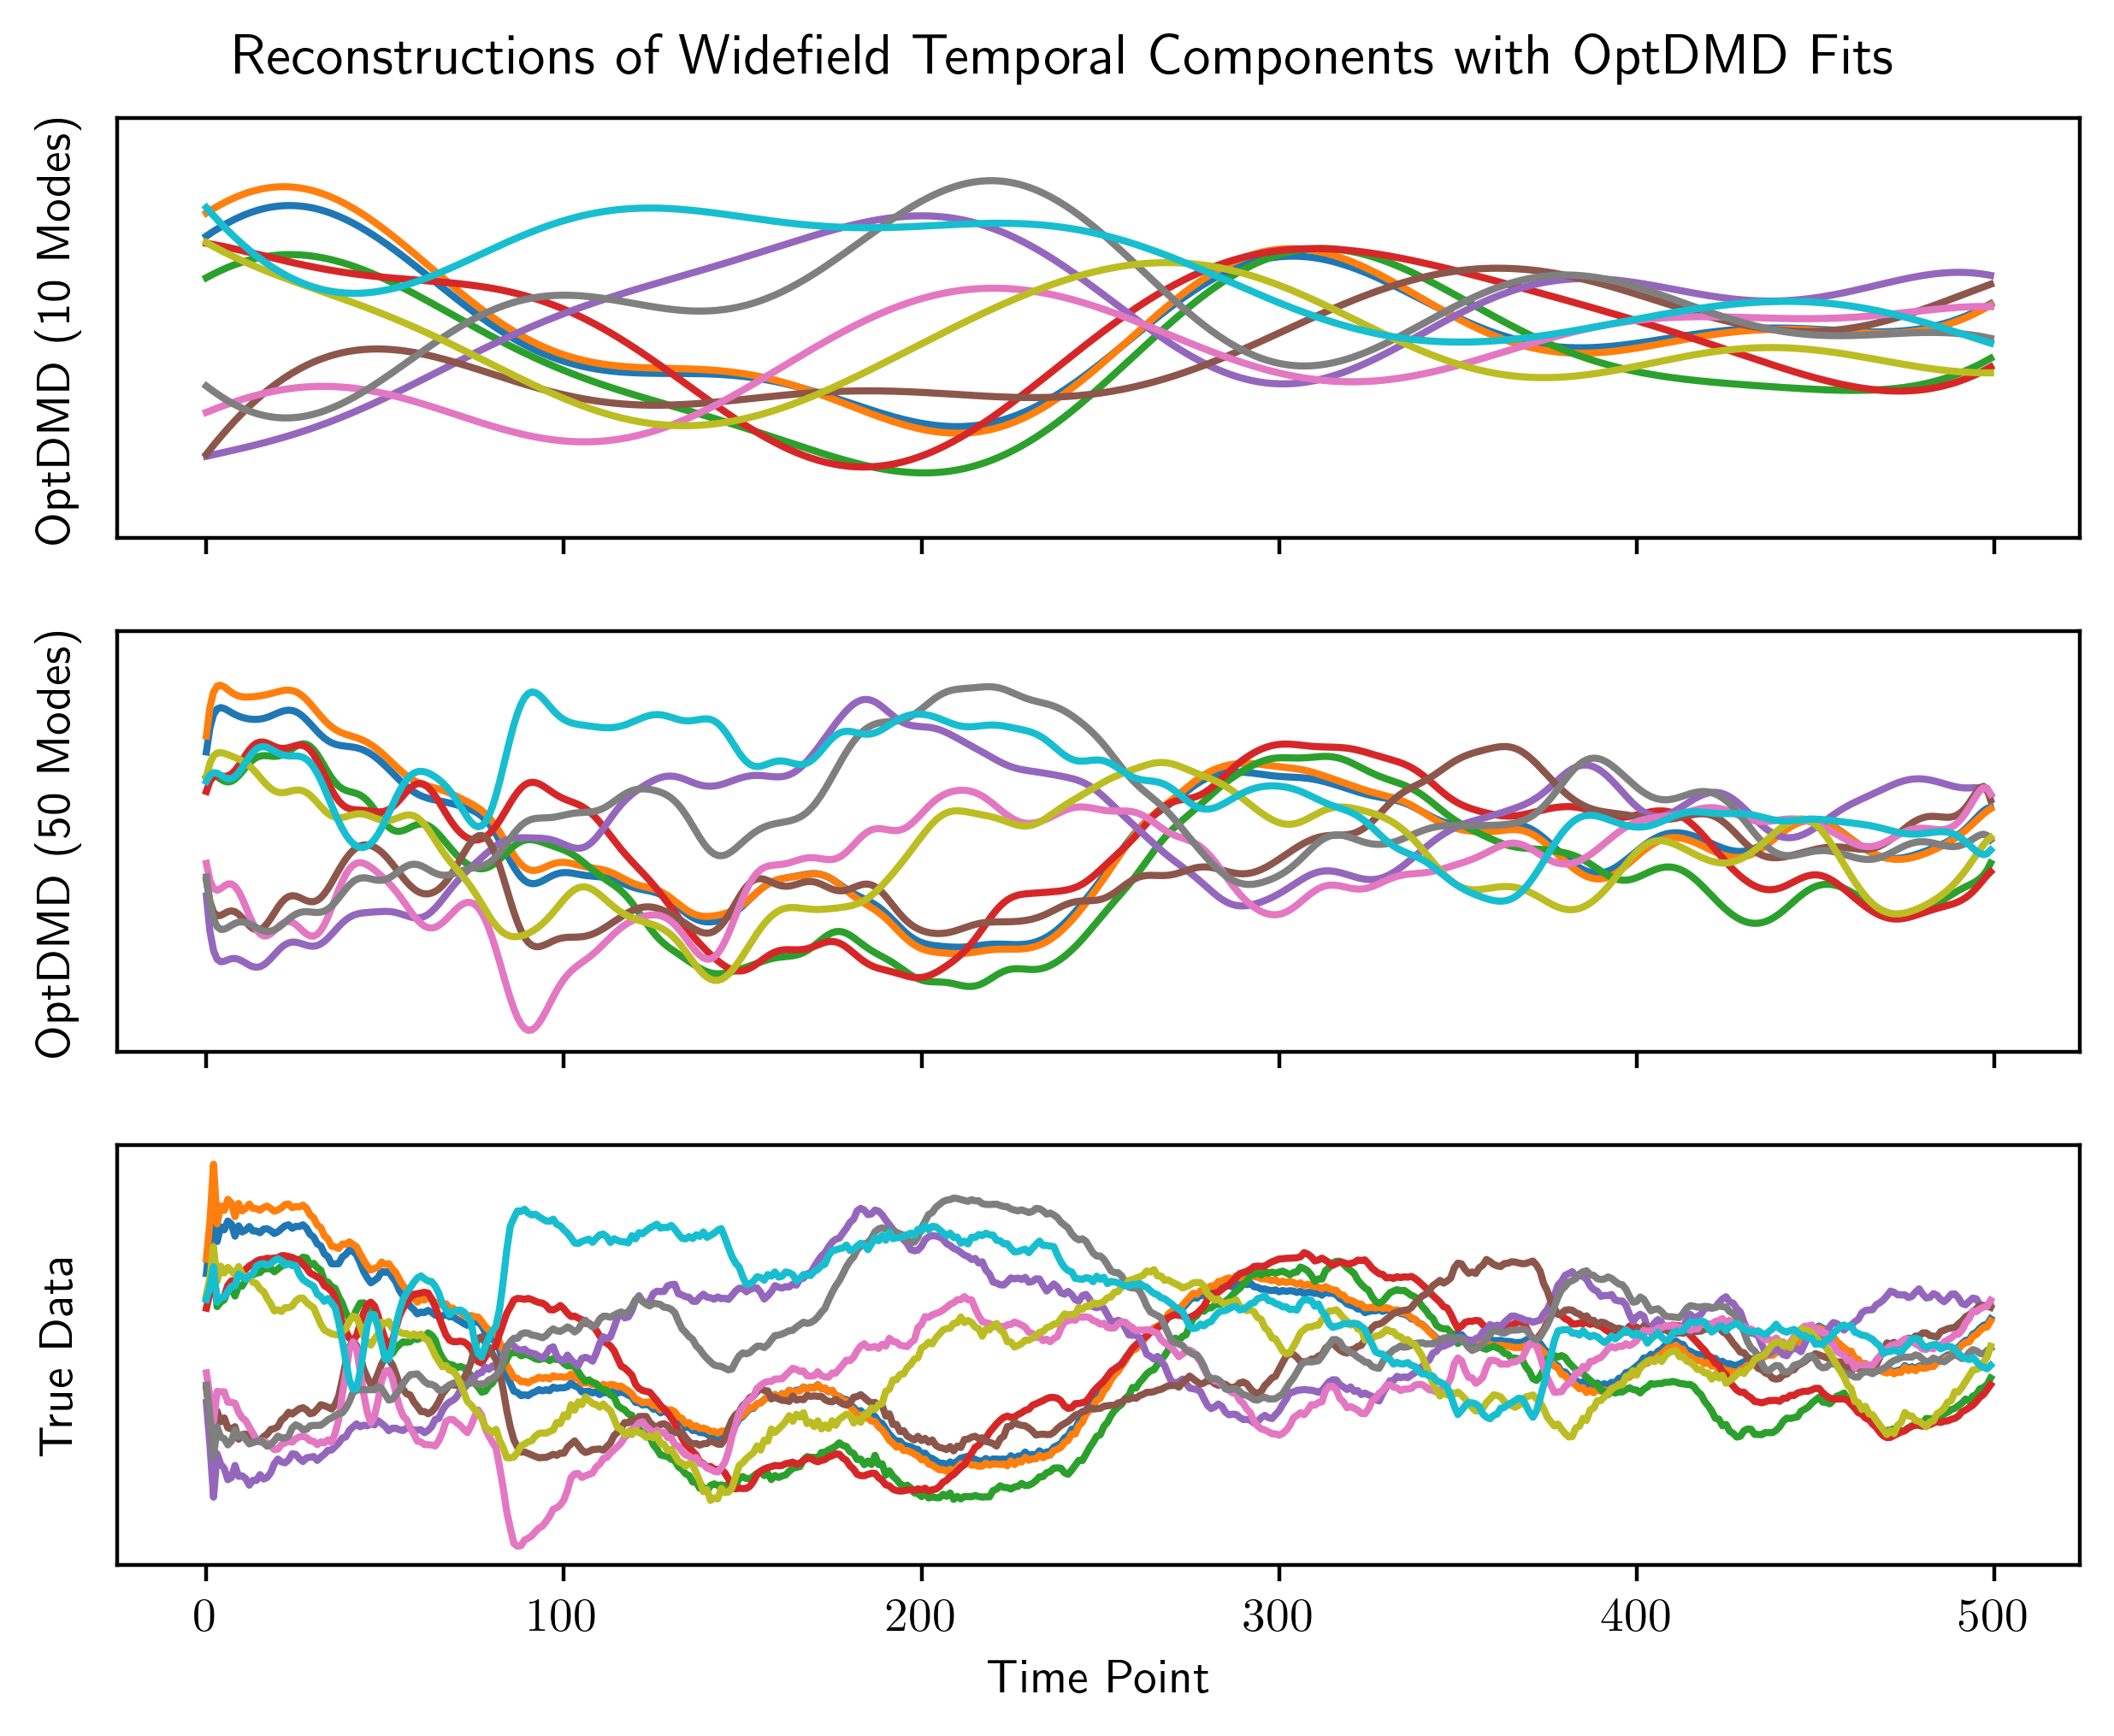

In [51]:
fig,ax = plt.subplots(3,1,sharex=True,sharey=True)
fig.tight_layout()
optdmd10 = BOPDMD(svd_rank=10,num_trials=0)
optdmd10.fit(V[:50,:500],np.arange(500))
optdmd50 = BOPDMD(svd_rank=50,num_trials=0)
optdmd50.fit(V[:50,:500],np.arange(500))
for i in range(10):
    ax[0].plot(np.real(optdmd10.reconstructed_data[i,:]))
    ax[0].set_ylabel("OptDMD (10 Modes)")
    ax[0].set_yticks([])
    ax[1].plot(np.real(optdmd50.reconstructed_data[i,:]))
    ax[1].set_ylabel("OptDMD (50 Modes)")
    ax[1].set_yticks([])
    ax[2].plot(np.real(V[i,:500]))
    ax[2].set_ylabel("True Data")
    ax[2].set_yticks([])
ax[2].set_xlabel("Time Point");
fig.suptitle("Reconstructions of Widefield Temporal Components with OptDMD Fits",y=1.01);

While there is significant overfitting happening, it's pretty amazing to me that the fit with 50 components is reproducing the denoised data almost flawlessly with what is essentially a linear dynamical system.

We can do further hyperparameter tuning by changing the different hyperparameters used for the nonlinear least squares algorithm, variable projection. However, I have not found changing those from the defaults to have any significant positive effect on performance, so I will not go into that here.


DMD and its variants are not good methods for forecasting future data. With OptDMD, we have simply fit linear combinations of exponentials to our data, and thus there is nothing constraining these exponentials from blowing up or decaying to zero as soon as the training window ends. The following plots demonstrate this by plotting the forecast 50 time stamps beyond the training period, or about 1.4 seconds into the future.

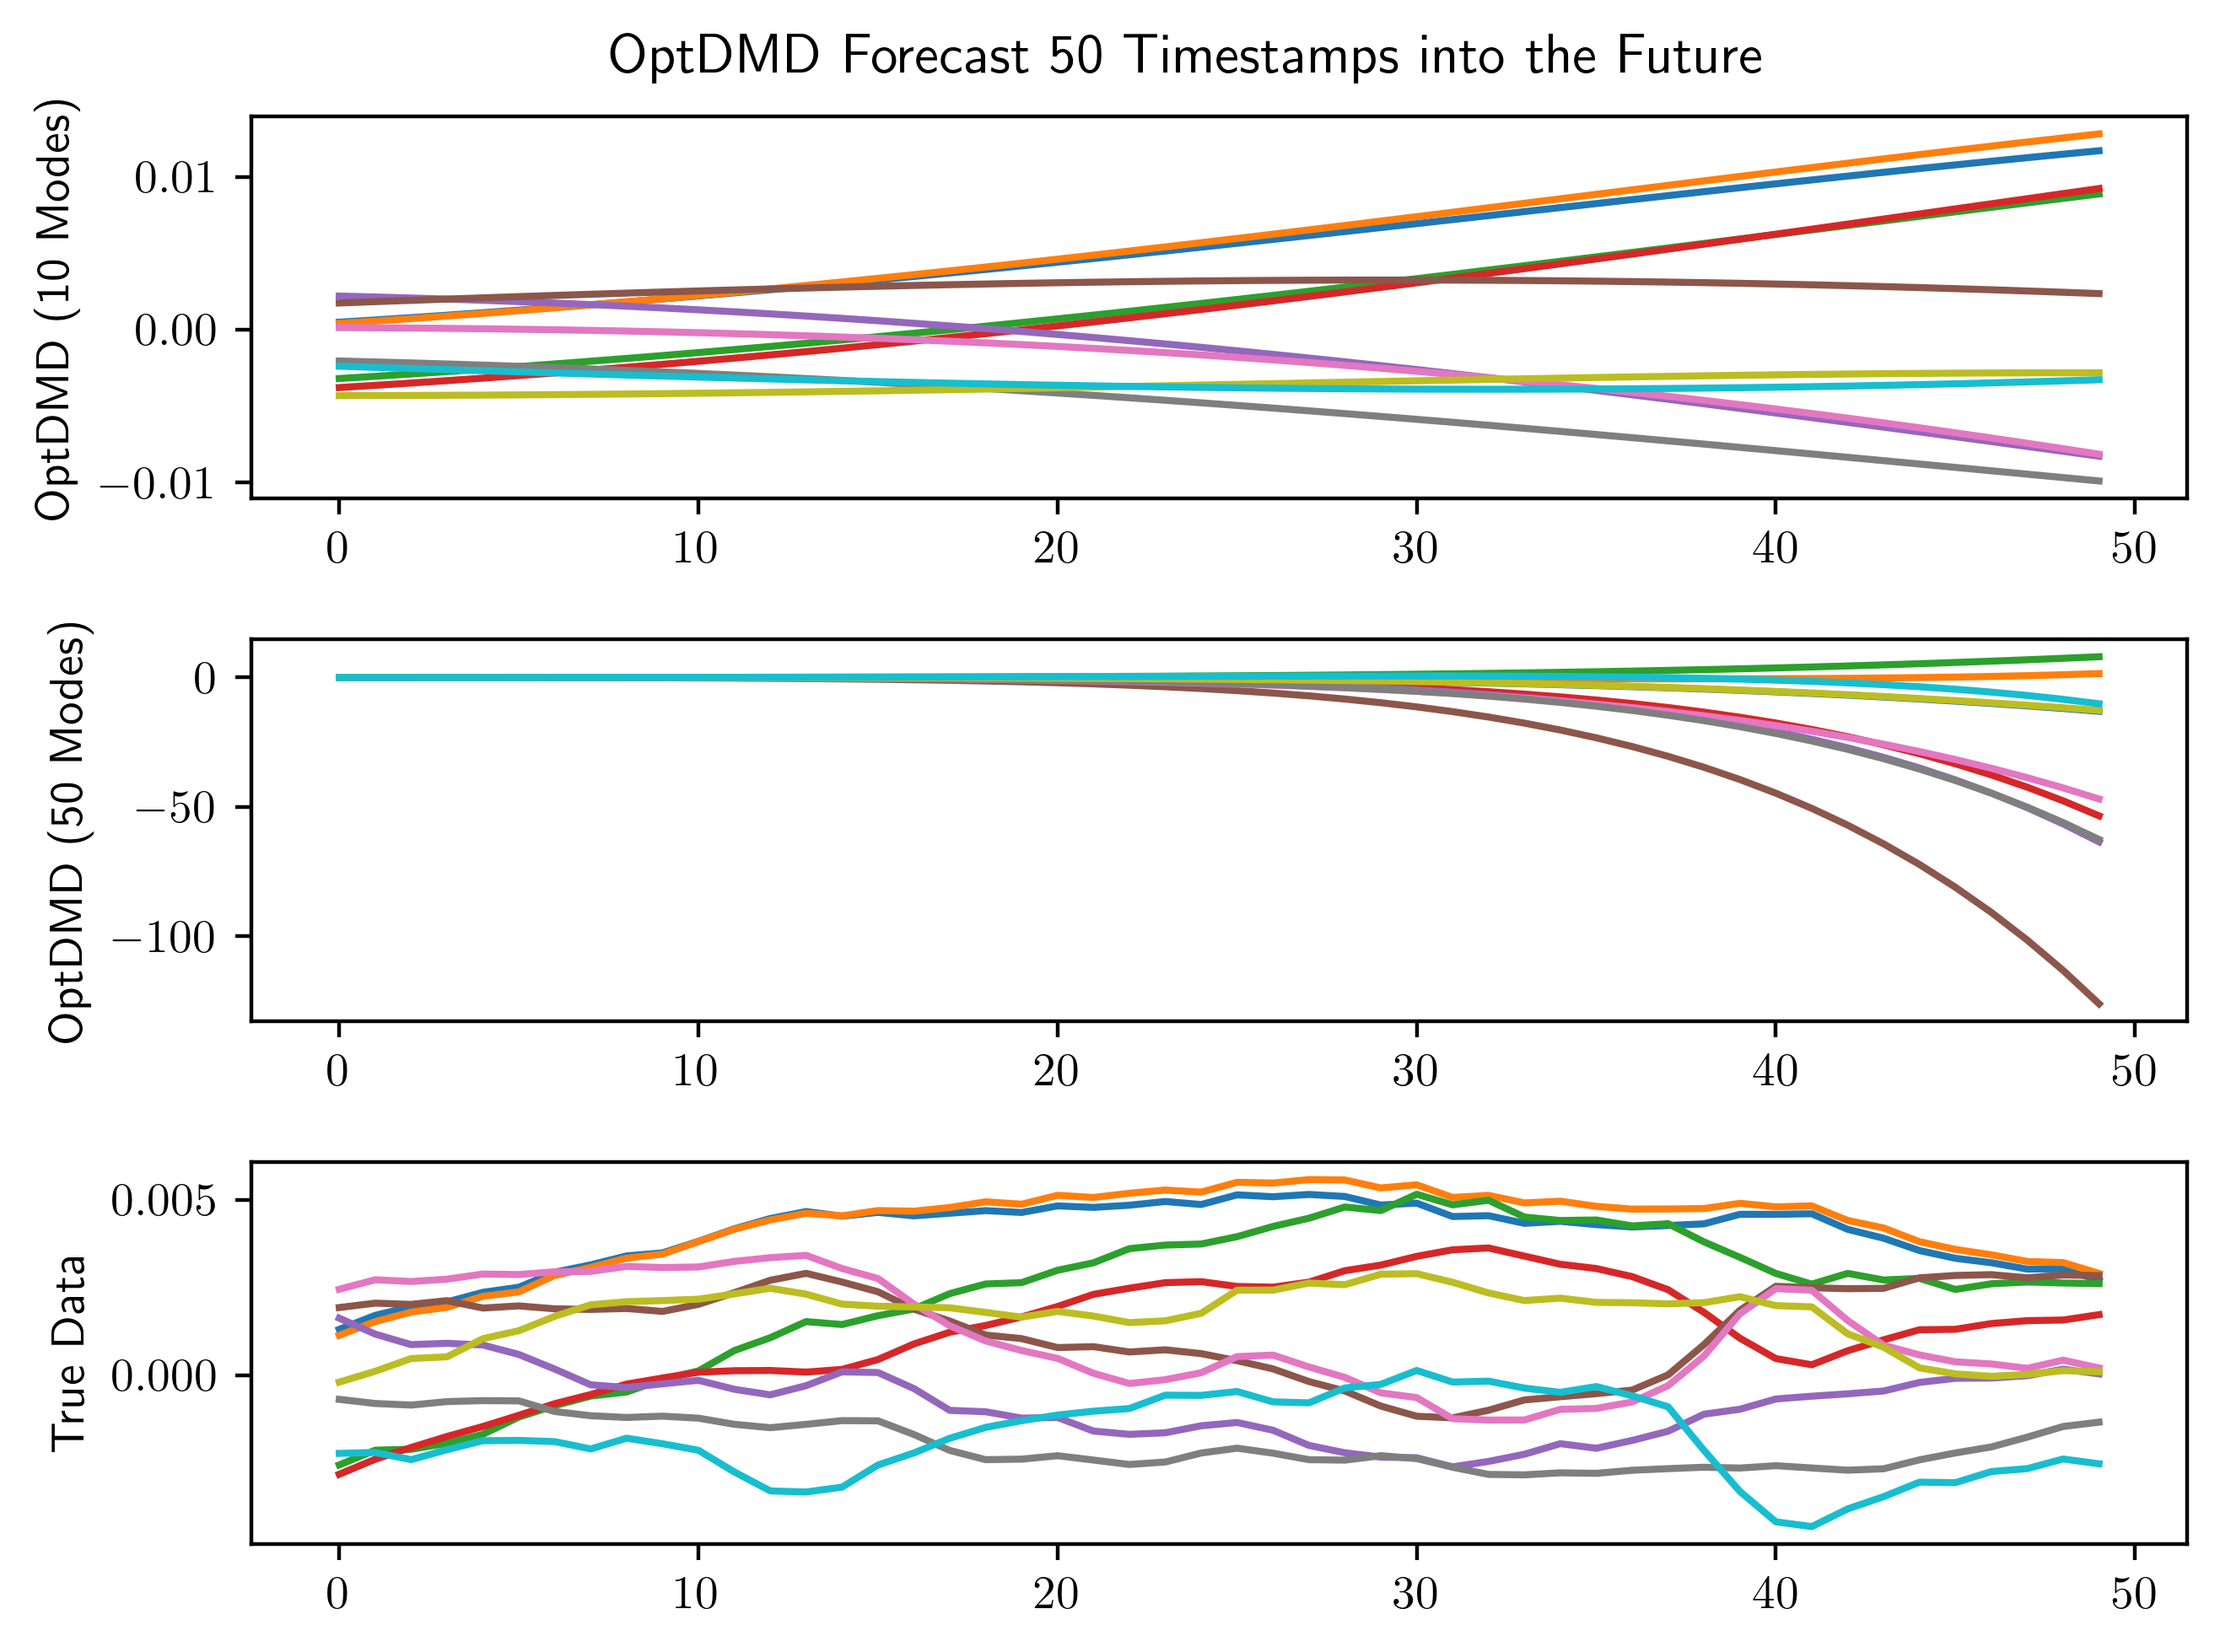

In [18]:
fig,ax = plt.subplots(3,1)
fig.tight_layout()
forecast10 = np.real(optdmd10.forecast(np.arange(500,550)))
forecast50 = np.real(optdmd50.forecast(np.arange(500,550)))
for i in range(10):
    ax[0].plot(forecast10[i,:])
    ax[0].set_ylabel("OptDMD (10 Modes)")
    ax[1].plot(forecast50[i,:])
    ax[1].set_ylabel("OptDMD (50 Modes)")
    ax[2].plot(V[i,500:550])
    ax[2].set_ylabel("True Data")
fig.suptitle("OptDMD Forecast 50 Timestamps into the Future",y=1.01);

Note the different y axes. Both models diverge rather than reconstruct future data, with the more overfit model doing so much faster. Intuitively, it does not really make sense for deterministic models like OptDMD to make good predictions about neural data anyway, because brains are not purely deterministic (or at least are not modeled well as purely deterministic with the tools we have today).

We can also quantify the relative significance of each mode by plotting the weights (the $b_j$'s) of each mode in the reconstruction, in a matter analogous to plotting the singular values of an SVD. We will sort the amplitudes from largest to smallest.

Text(0.5, 1.01, 'Amplitudes of OptDMD Fits with Different Number of Modes')

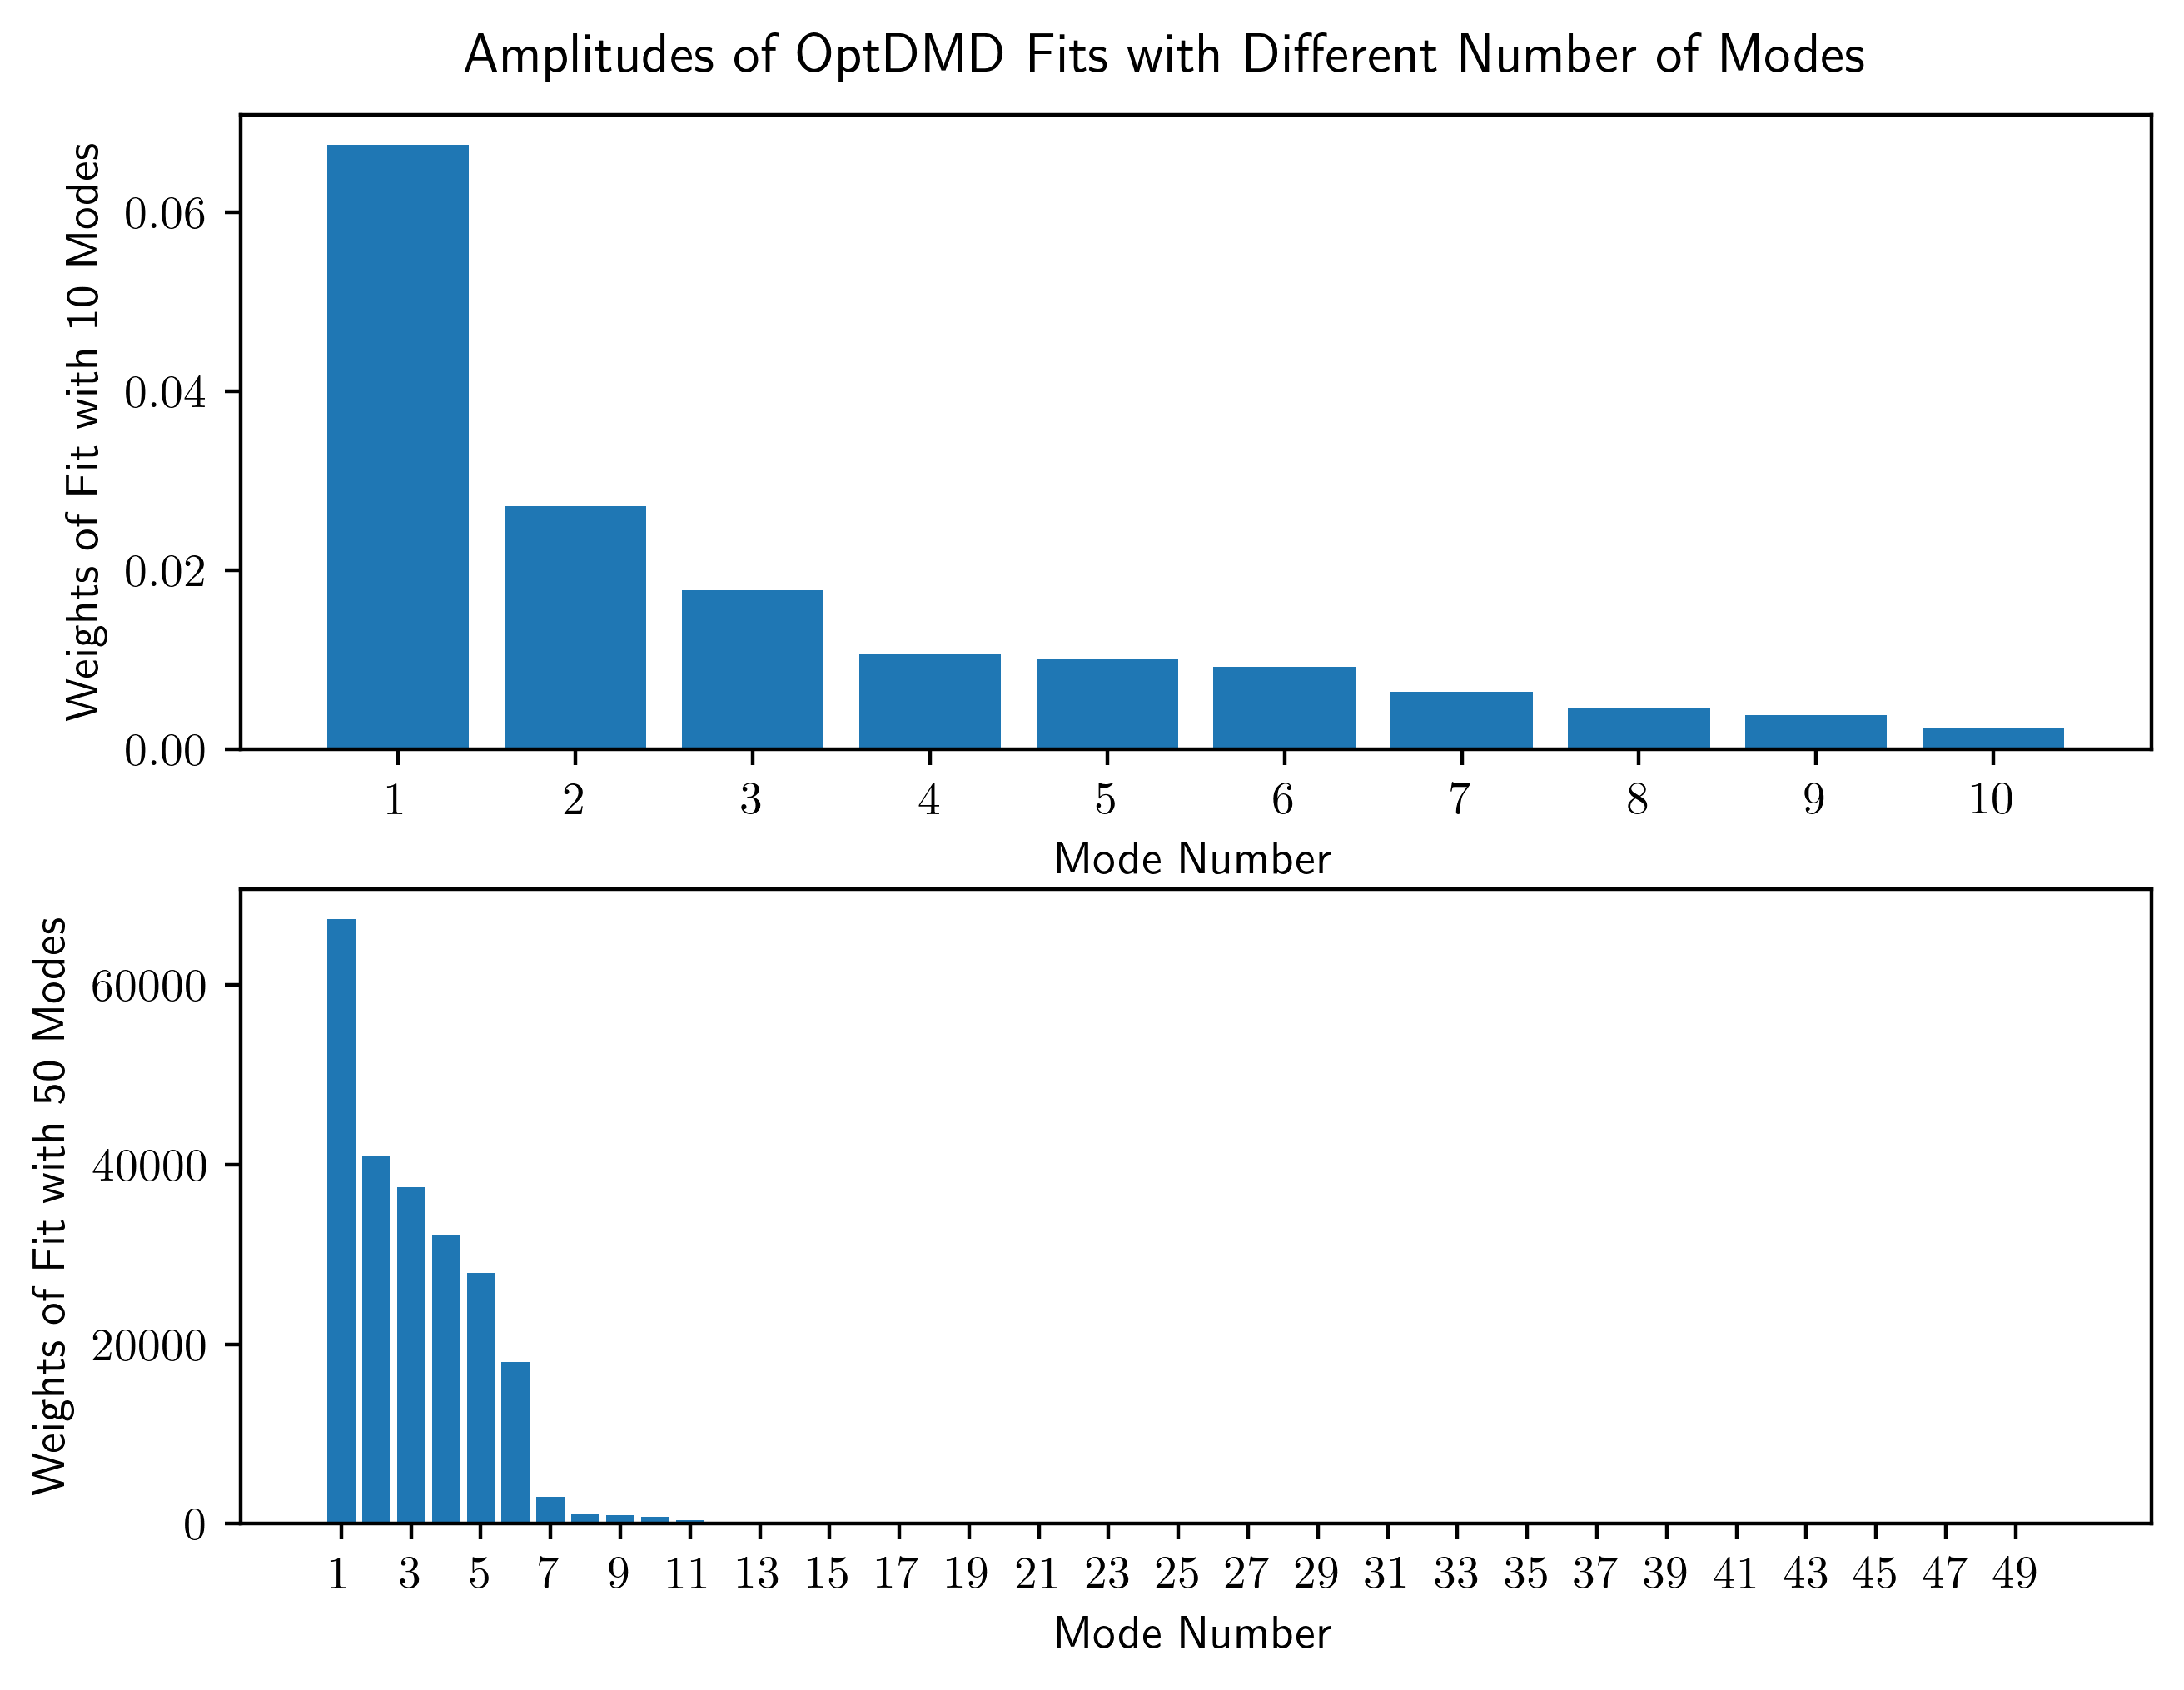

In [19]:
fig, ax = plt.subplots(2,1)
fig.tight_layout()
idx10 = np.argsort(optdmd10.amplitudes)[::-1]
idx50 = np.argsort(optdmd50.amplitudes)[::-1]
ax[0].bar(np.arange(1,11),optdmd10.amplitudes[idx10])
ax[0].set_ylabel("Weights of Fit with 10 Modes")
ax[0].set_xlabel("Mode Number")
ax[0].set_xticks(np.arange(1,11))
ax[1].bar(np.arange(1,51),optdmd50.amplitudes[idx50])
ax[1].set_ylabel("Weights of Fit with 50 Modes")
ax[1].set_xlabel("Mode Number")
ax[1].set_xticks(np.arange(1,51,2))
fig.suptitle("Amplitudes of OptDMD Fits with Different Number of Modes",y=1.01)

It is clear that, especially in the 50 mode case, most of the modes contribute relatively little if anything. As a more rigorous way to determine the correct numbr of modes, we can compute the optimal hard threshold for the SVD with the formula in the paper here: https://arxiv.org/pdf/1305.5870.pdf. For a $50\times 500$ matrix with unknown noise, the procedure is to discard singular values $\sigma$ smaller than $1.6089\sigma_{median}.$

In [20]:
pca = PCA(n_components=50).fit(V[:50,:500])
print("Number of Singular Values above Hard Threshold: " + str(np.sum(pca.explained_variance_>1.6089*np.median(pca.explained_variance_))))

Number of Singular Values above Hard Threshold: 23


The way to interpret the number $23$ here is that singular values $24-50$ contribute more noise than signal to the reconstruction (at least in the limit that our matrix dimensions become very large), and therefore we should truncate at 23. That isn't to say that we need exactly $23$ modes to get a good approximation of our data, but that including modes $24-50$ (asymptotically) does not improve our reconstruction.

Although I am not sure how rigorous it is, applying the same formula to the amplitudes produces a similar result:

In [21]:
print("Number of Amplitudes above Hard Threshold: " + str(np.sum(optdmd50.amplitudes > np.median(optdmd50.amplitudes)*1.6089)))

Number of Amplitudes above Hard Threshold: 24


If it is valid to apply this formula to hard thresholding OptDMD modes rather than principal components, then the difference here could be due to the fact that our data is real but our eigenvalues are complex, and therefore we expect our modes to come in approximately complex-conjugate pairs. We will fit a 24-mode OptDMD below.

In [37]:
optdmd24 = BOPDMD(svd_rank=24,num_trials=0)
optdmd24.fit(V[:50,:500],np.arange(500))

In [38]:
print("10 mode RSE: " + str(RSE(optdmd10.reconstructed_data,V[:50,:500])))
print("24 mode RSE: " + str(RSE(optdmd24.reconstructed_data,V[:50,:500])))
print("50 mode RSE: " + str(RSE(optdmd50.reconstructed_data,V[:50,:500])))

10 mode RSE: 0.11399397988983294
24 mode RSE: 0.036289269408284086
50 mode RSE: 0.011896742016422882


So we see that the $24$ mode fit is a little more than $3$x better than the $10$ mode fit, while the $50$ mode fit is a little more than $3$x better than the $24$ mode fit. In terms of what these metrics say, the $10$ mode fit is nearly $9$x better at predicting the training data than guessing that the data equals its average value at each point, while the $50$ mode fit is about $84$x better. We can visualize more information about these fits with pyDMD's plotter function. This plots the variance captured by each singular value from the data, the eigenvalues in discrete-time, the eigenvalues in continuous time (scaled in size in proportion to their amplitudes), the top three modes (ranked by amplitude), and their dynamics (the time evolution of the associated exponential $e^{\lambda_jt}$).

First let's look at the plot summary for regular, exact DMD.

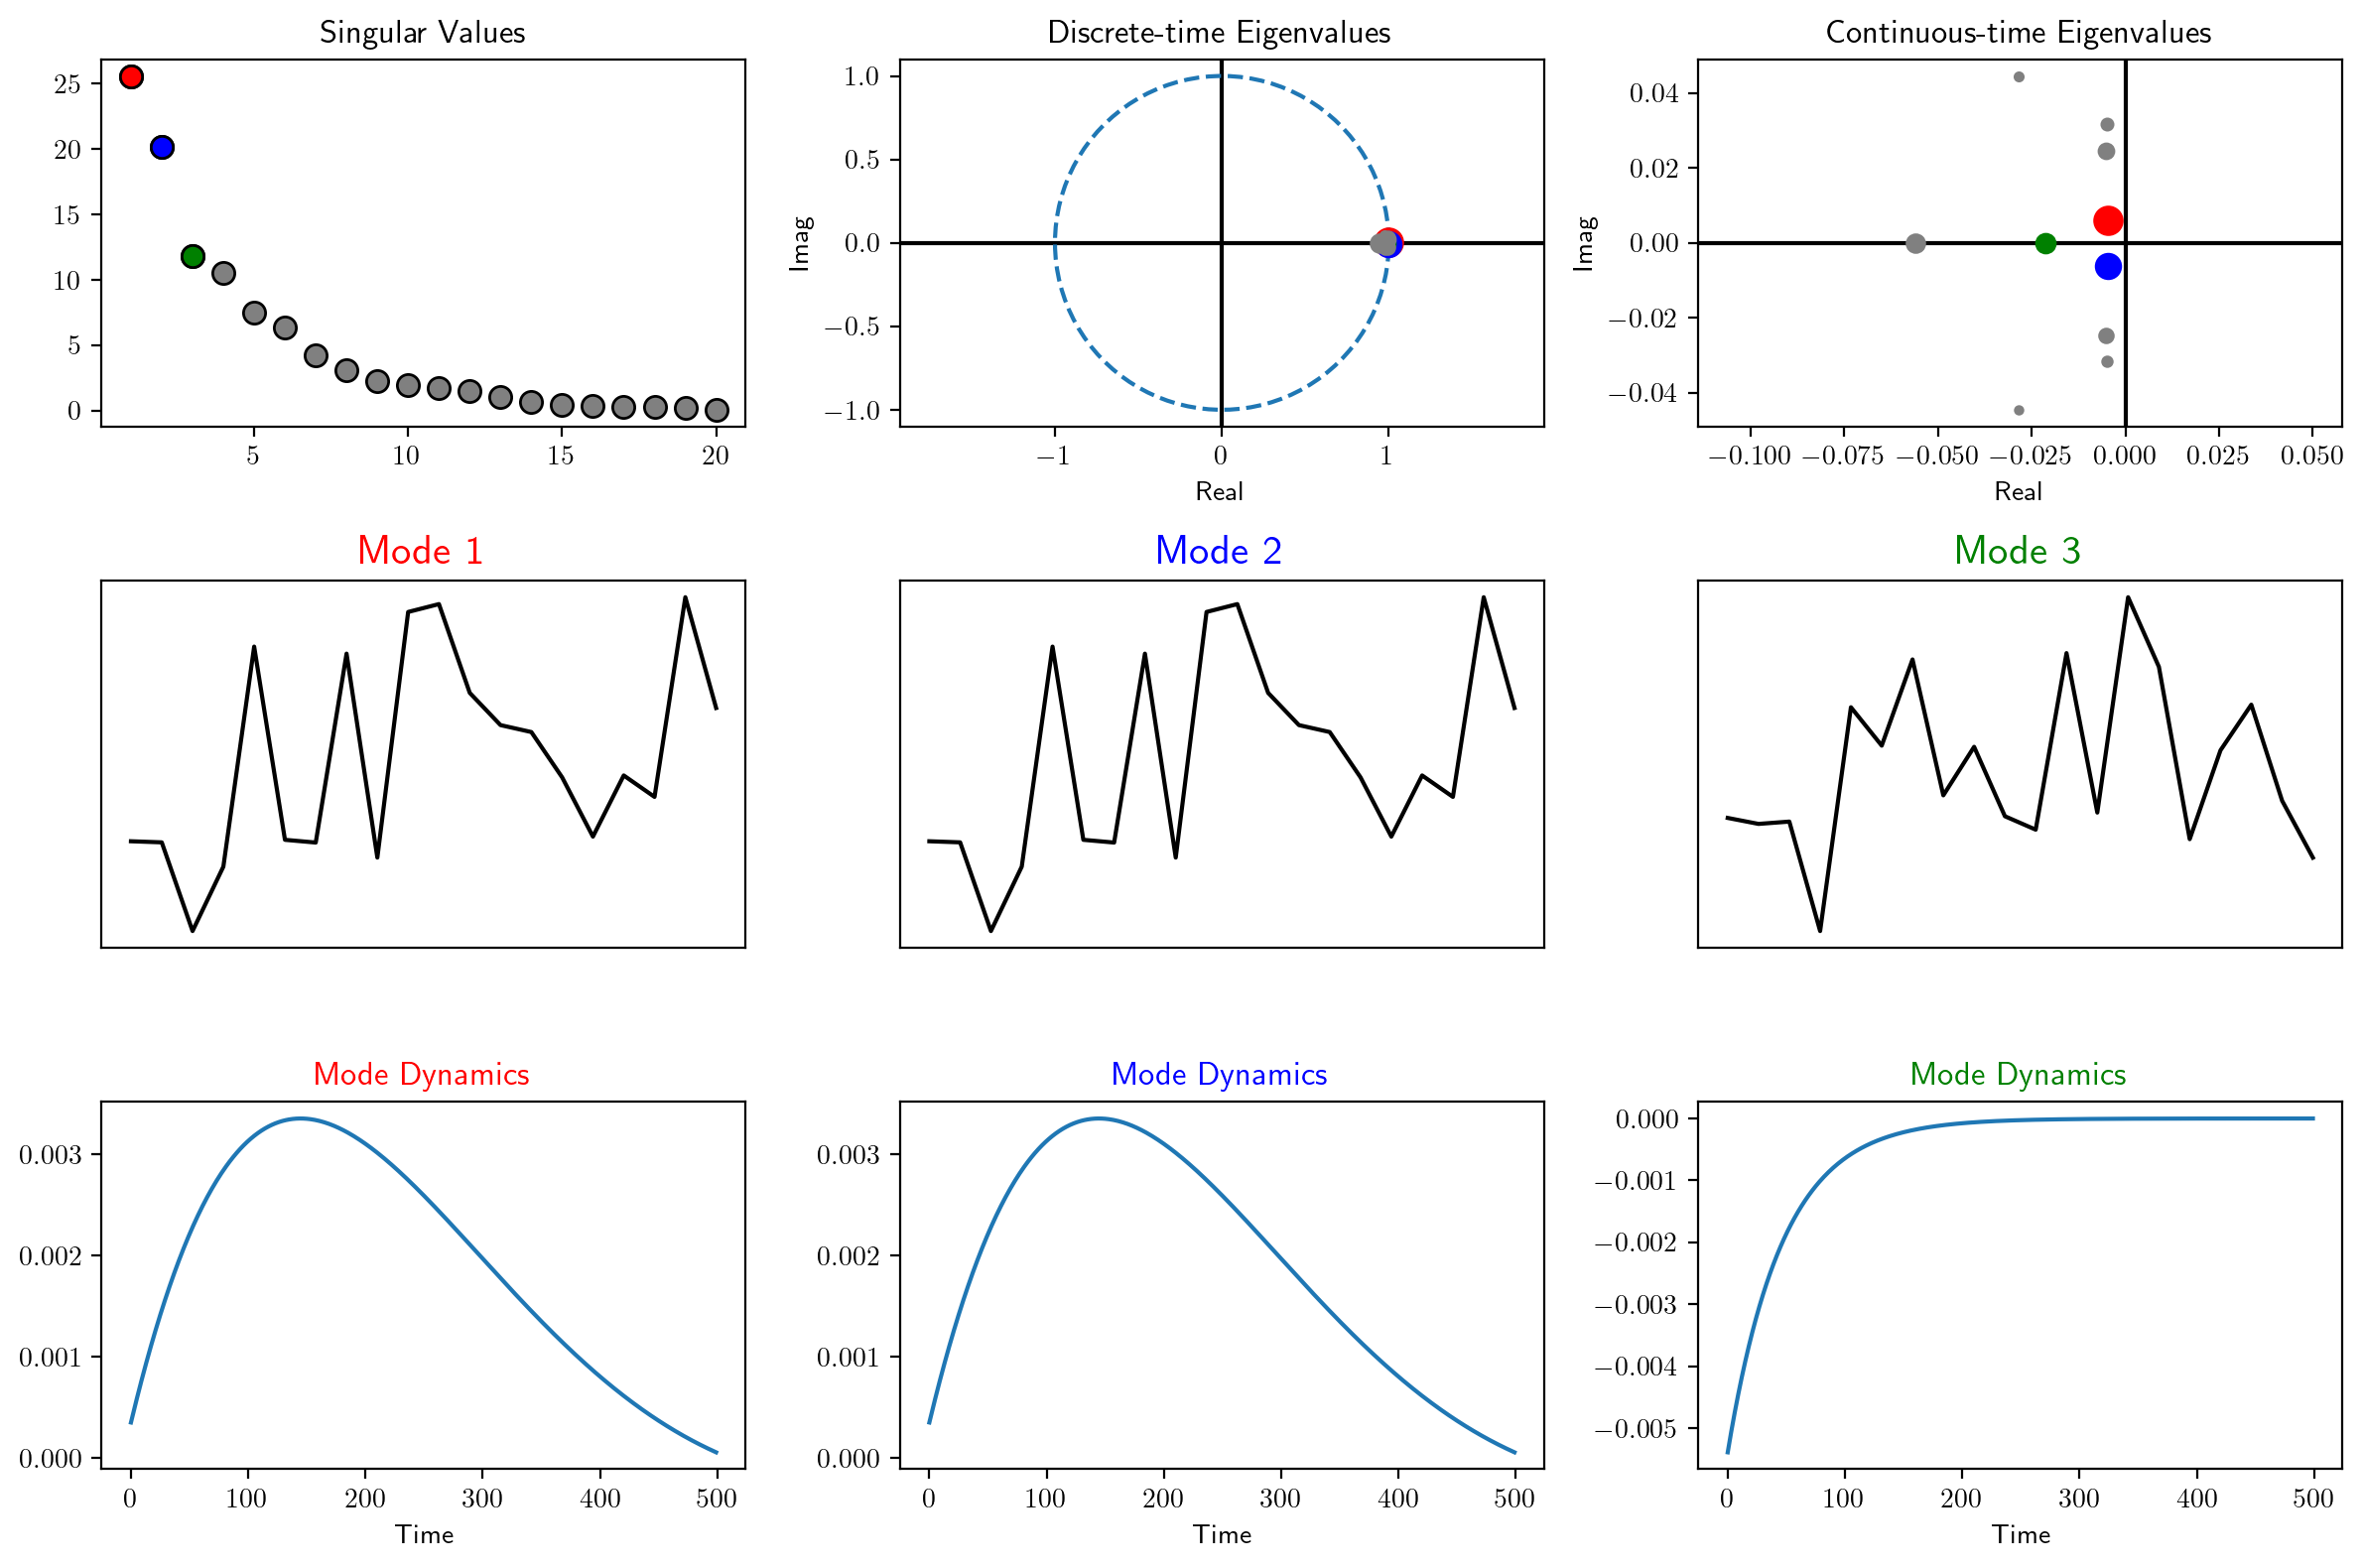

In [43]:
plotter.plot_summary(dmd_model_500_tp)

Next let's look at the plot summary for OptDMD with 10 modes.

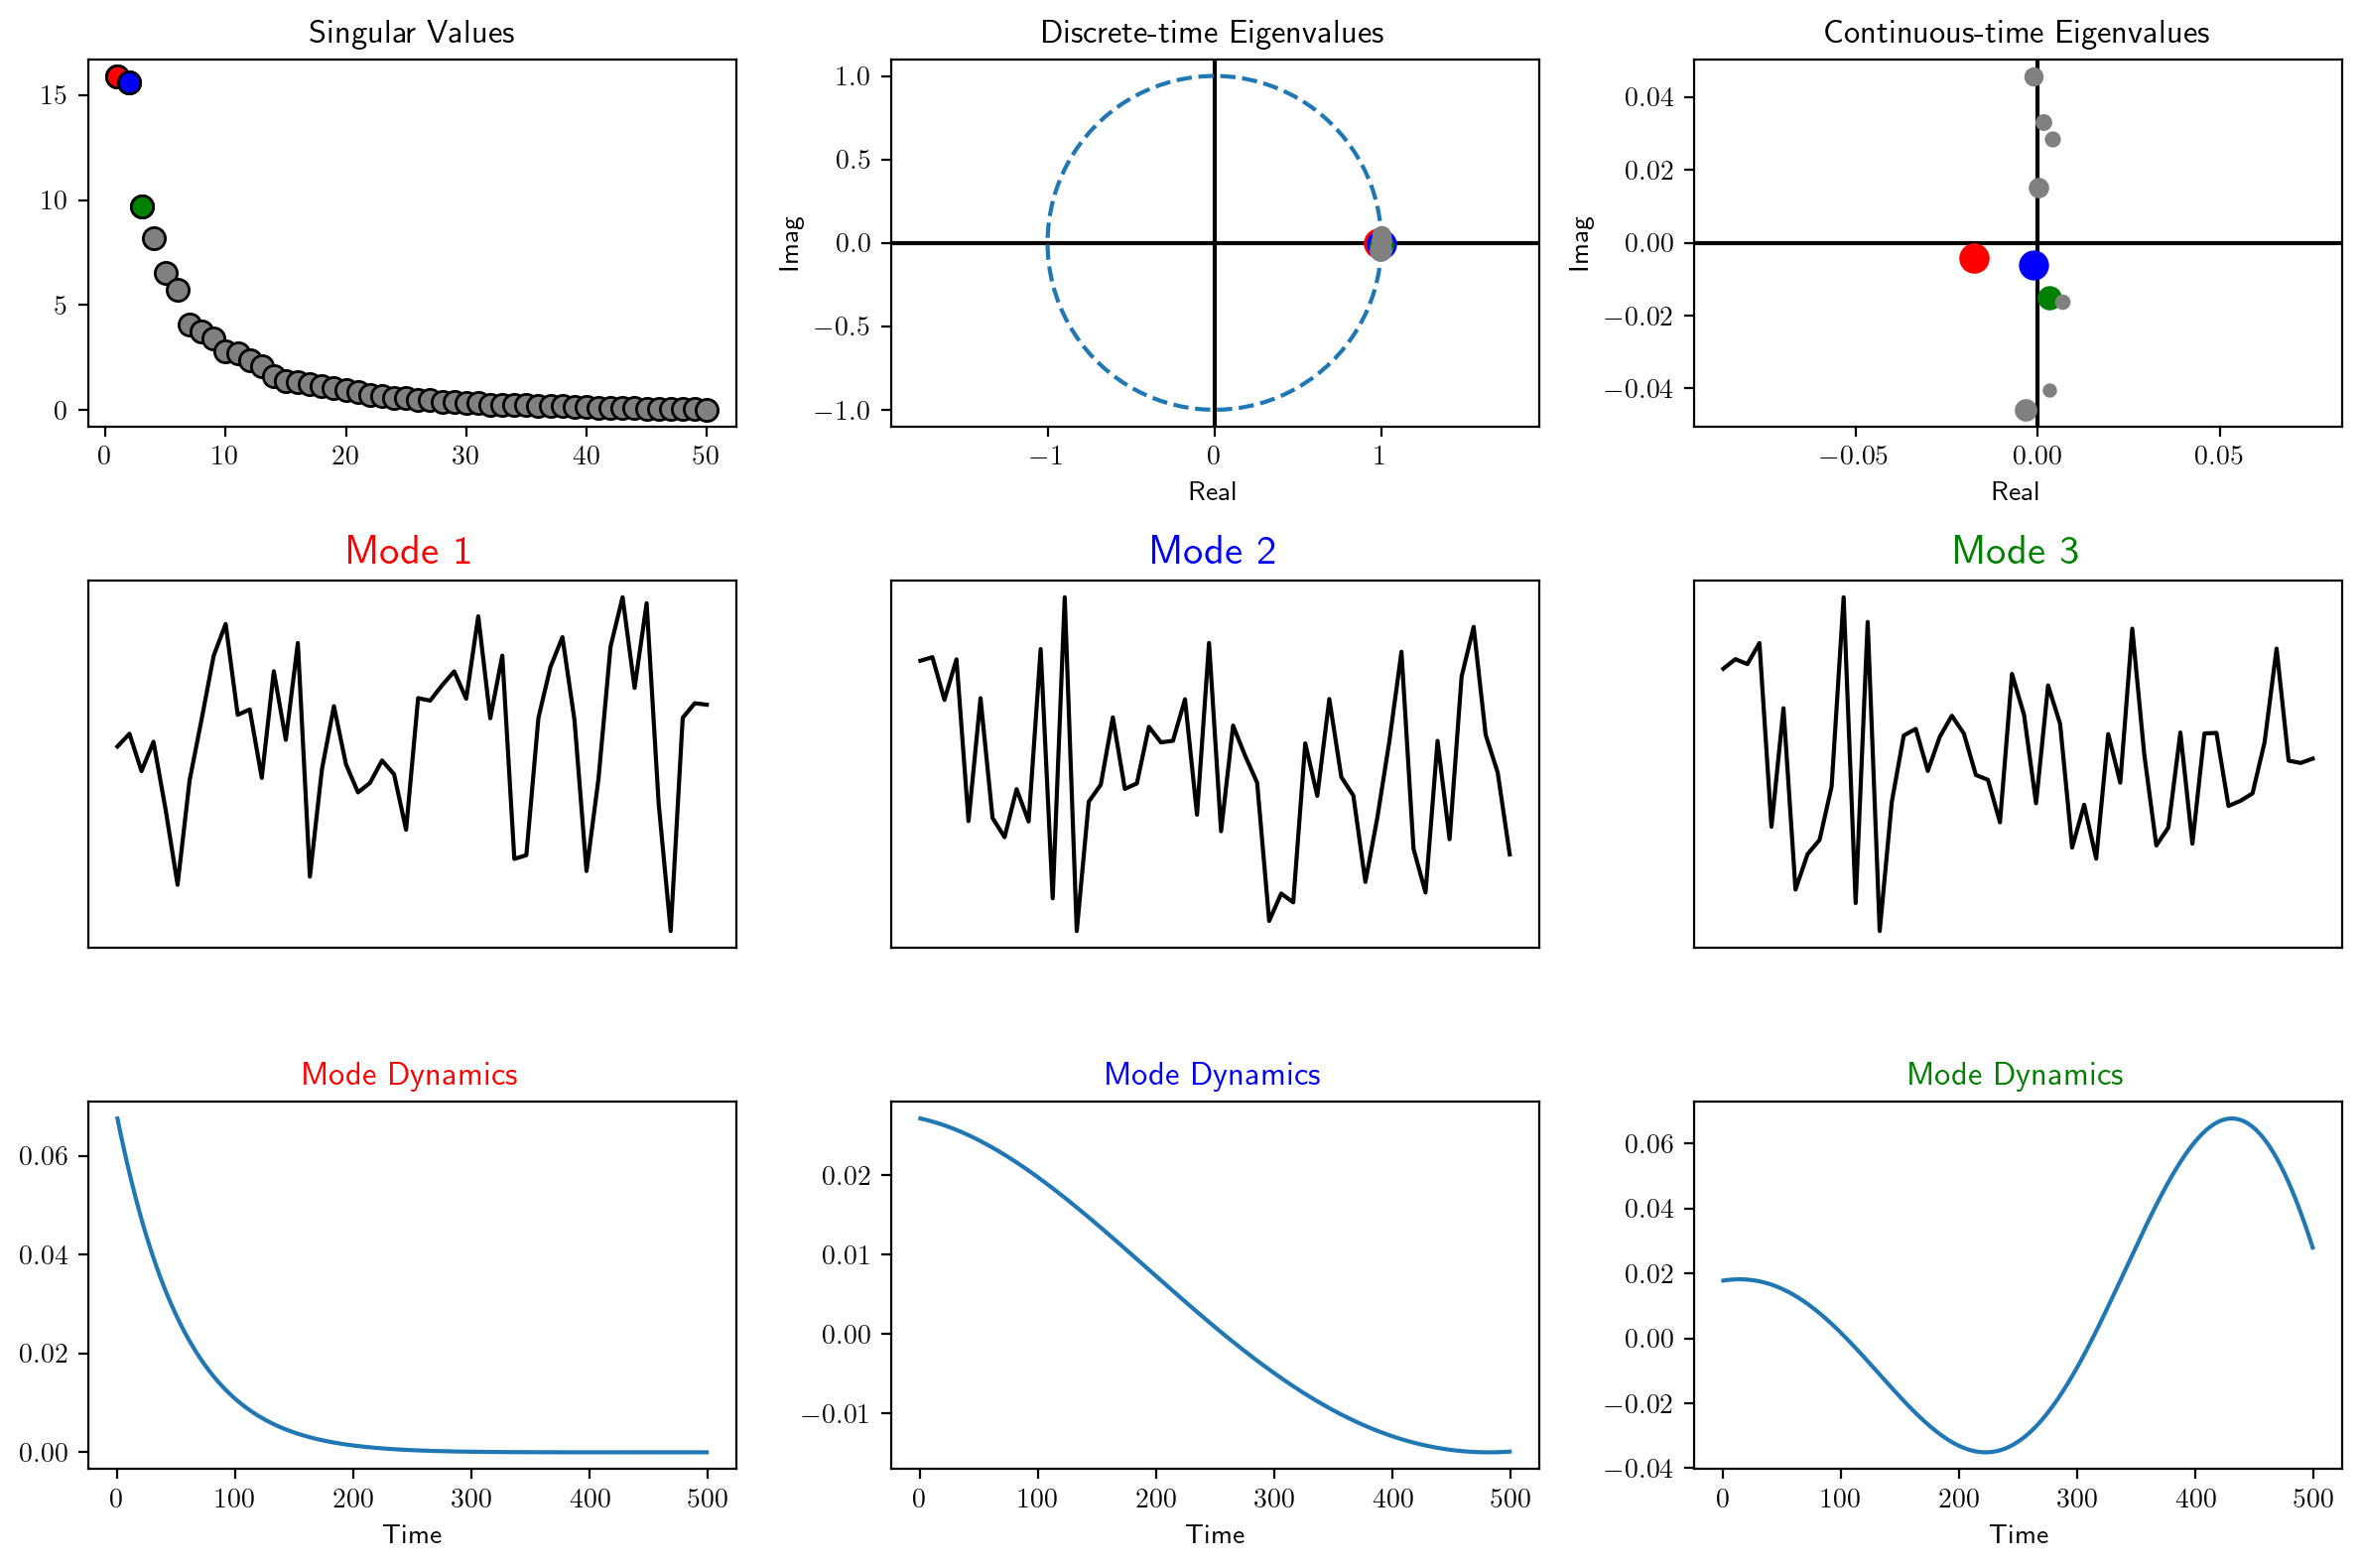

In [24]:
plotter.plot_summary(optdmd10)

Then for the $23$ mode fit.

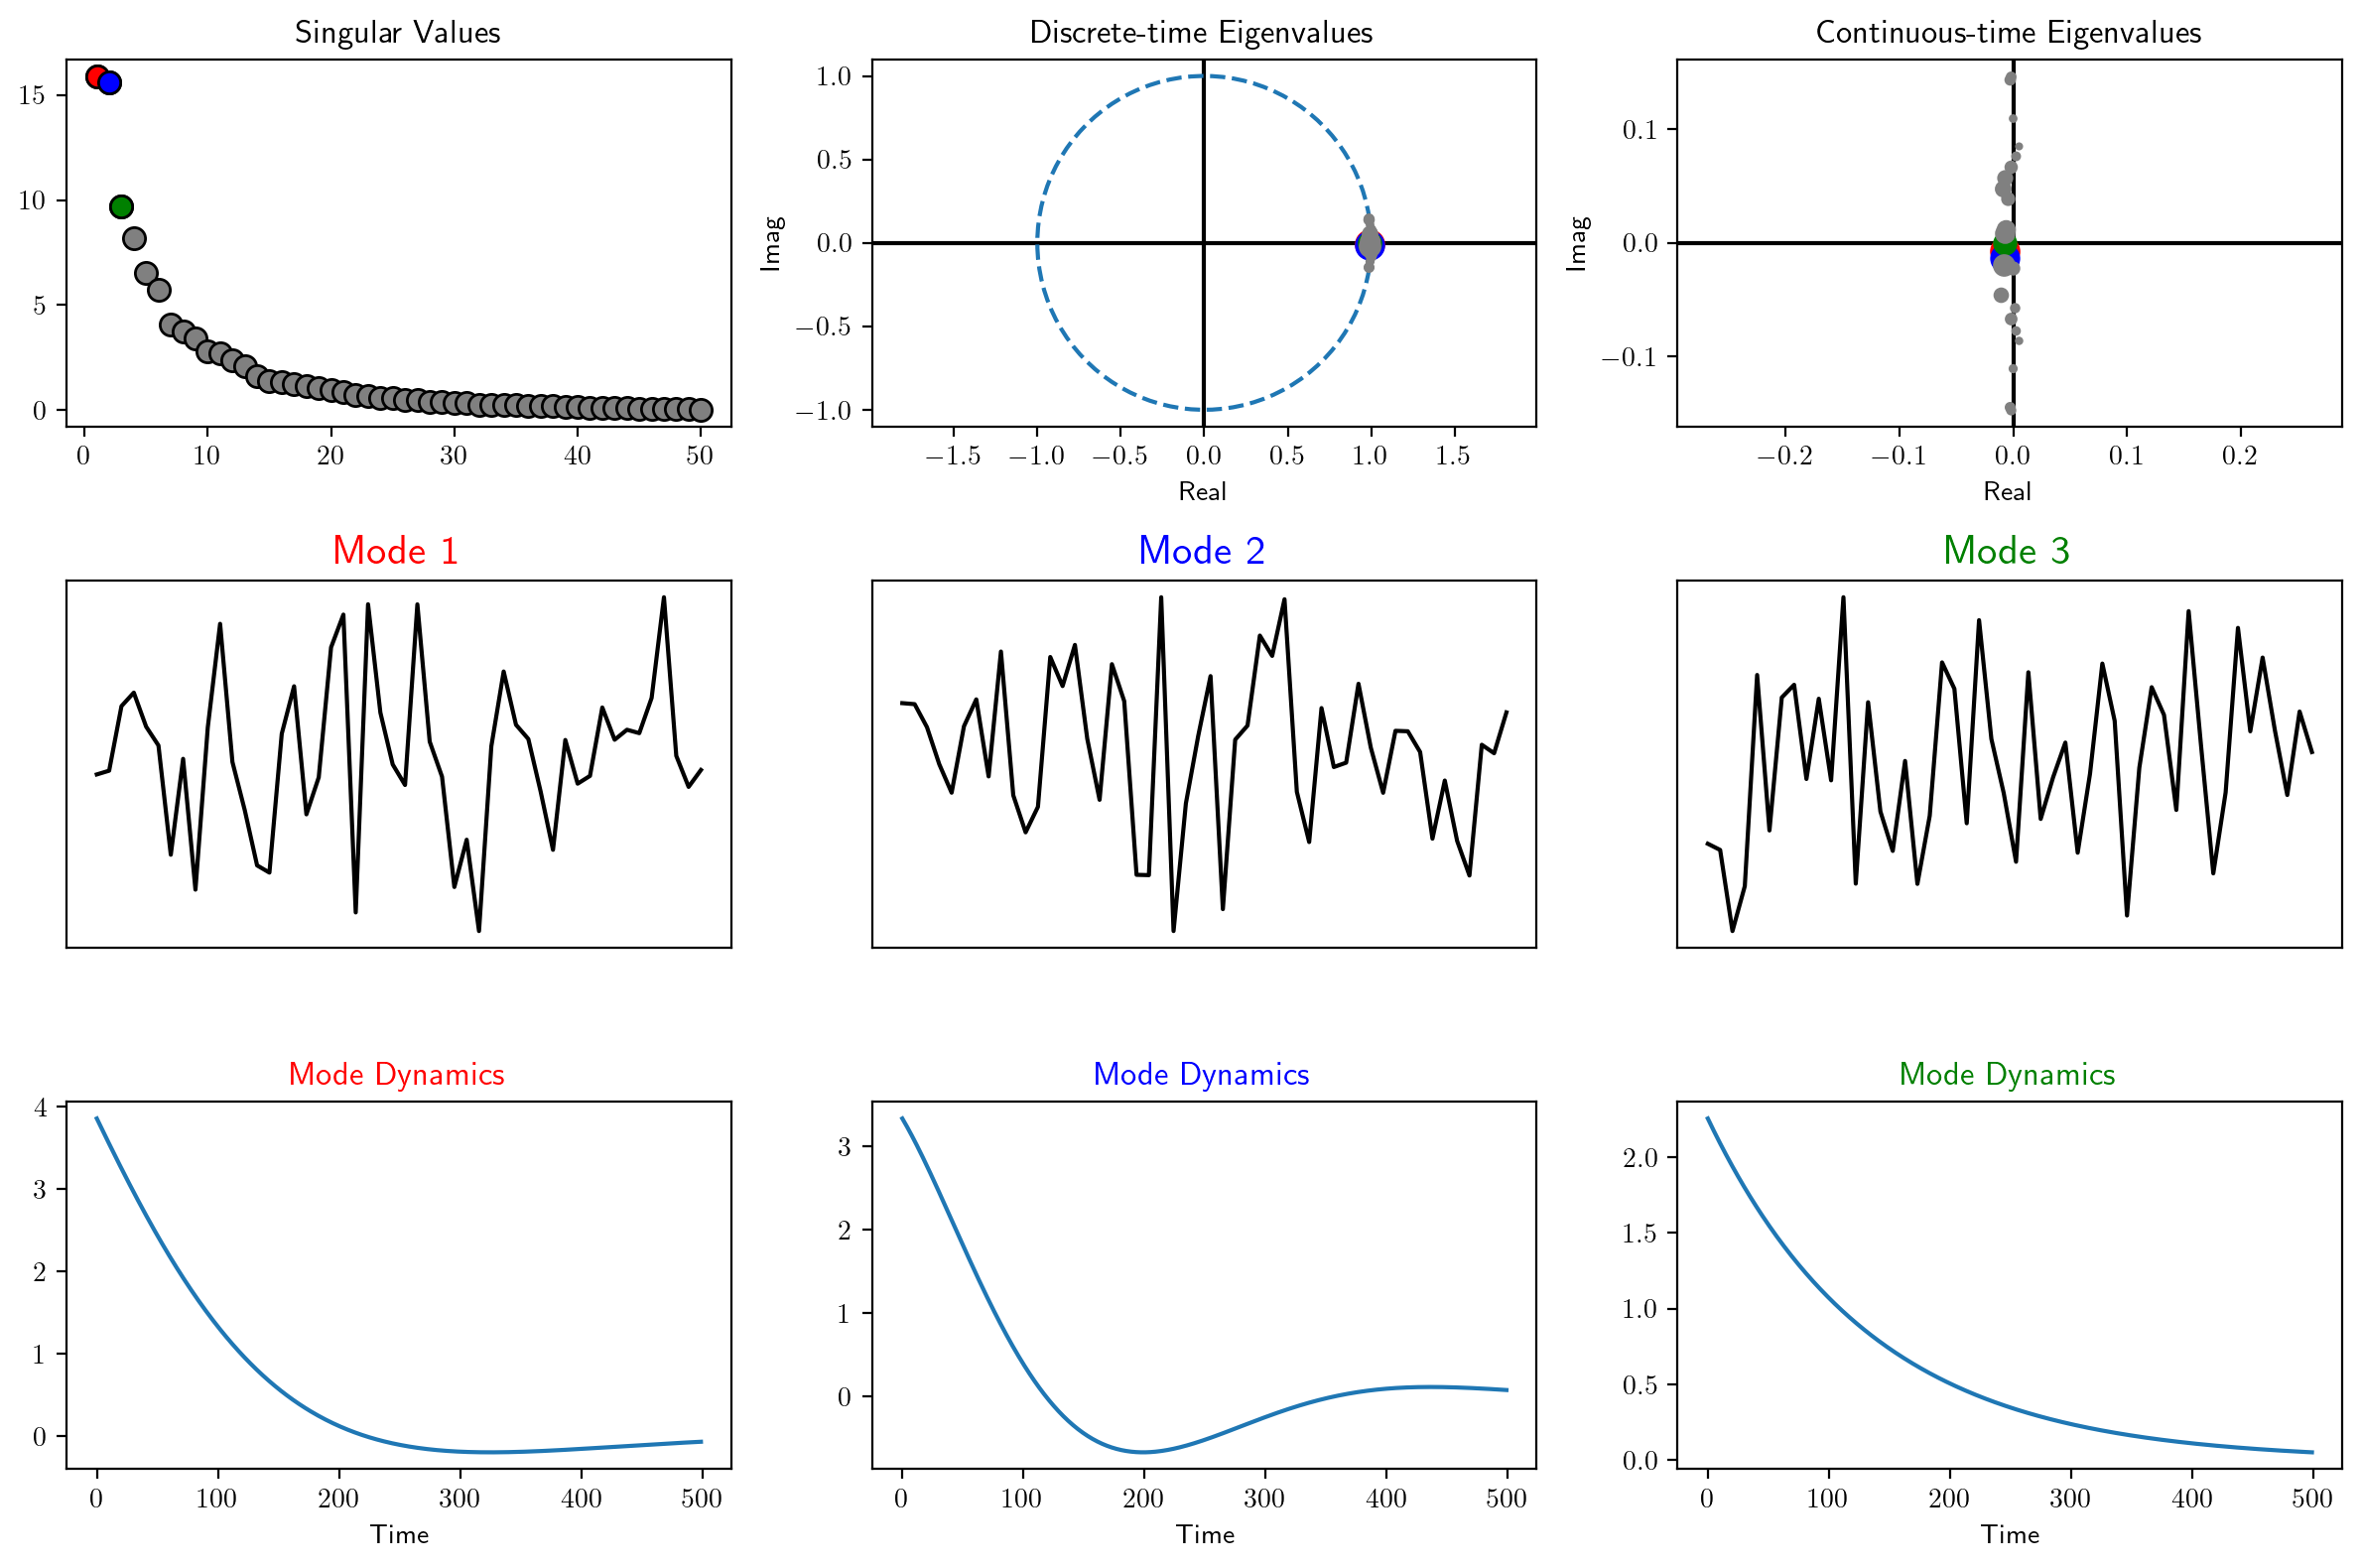

In [39]:
plotter.plot_summary(optdmd24)

Finally for the $50$ mode fit.

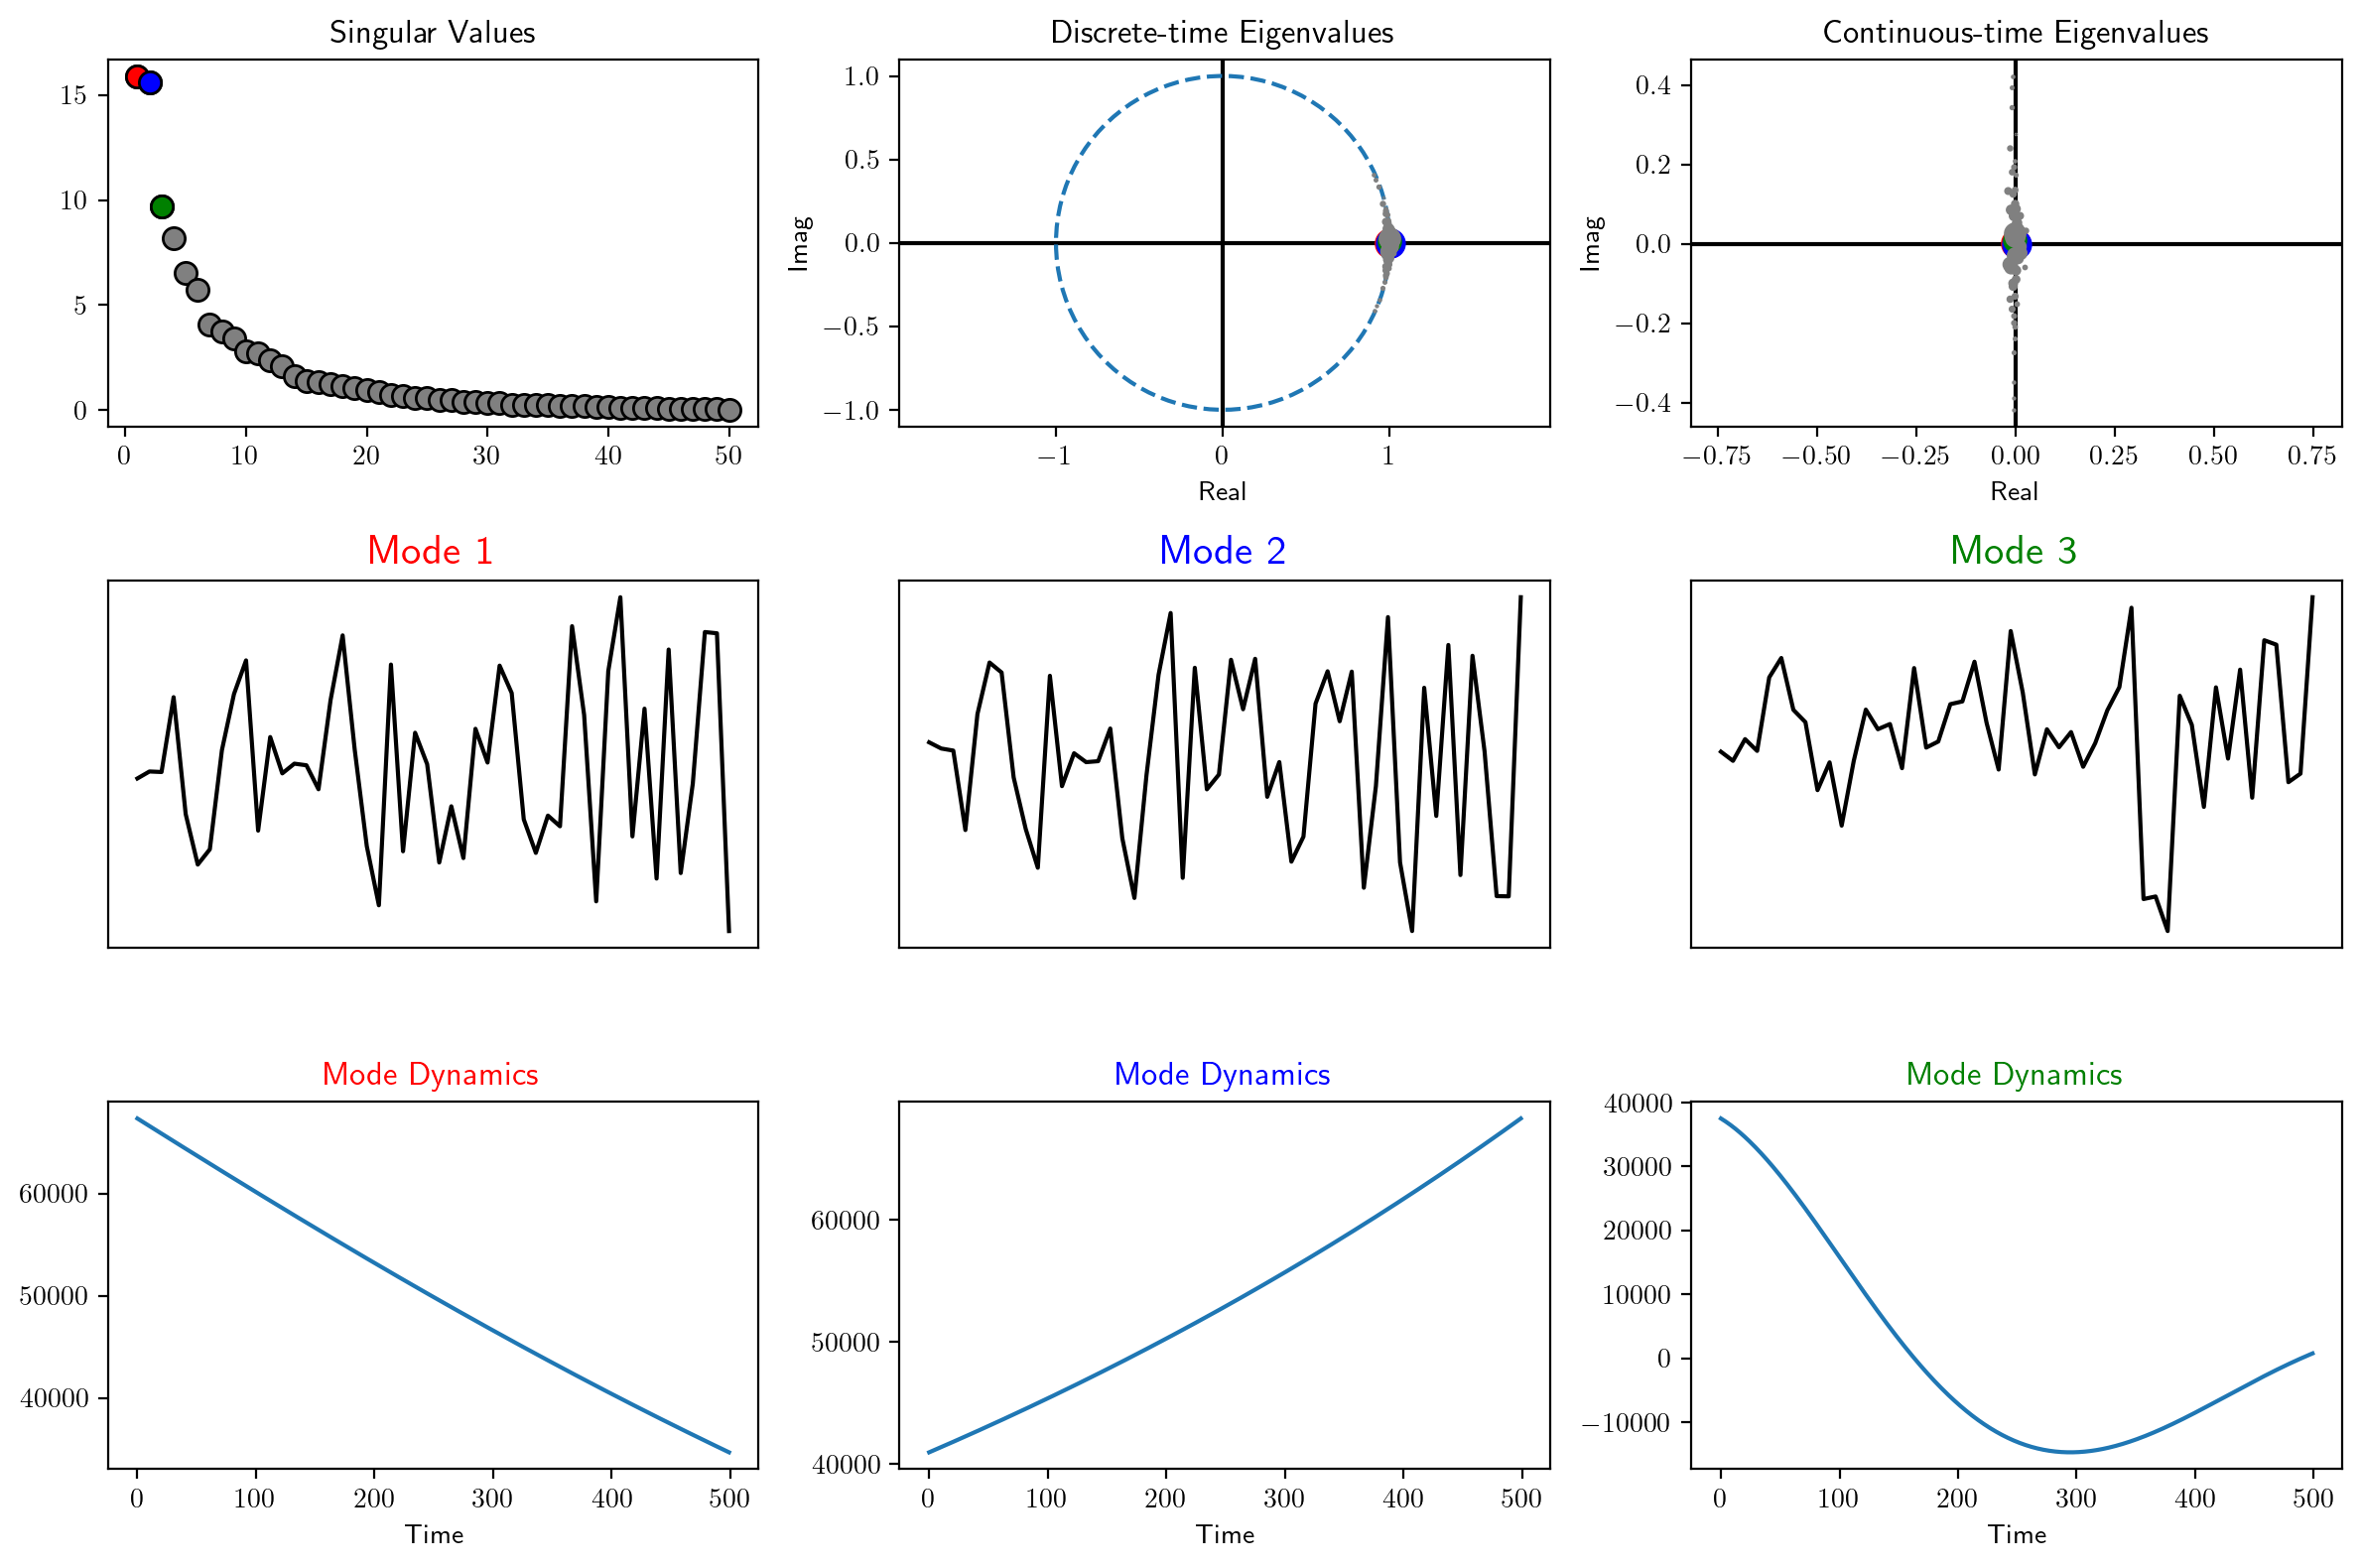

In [26]:
plotter.plot_summary(optdmd50)

The most notable difference between the plots for exact DMD and the plots for OptDMD to me is that all of the eigenvalues for exact DMD in their continuous time form lie to the left of the imaginary axis. This explains why the exact DMD solution quickly decays to zero. With the OptDMD fits, some of the eigenvalues lie to the left of the imaginary axis and some lie to the right. Thus, as some of the modes (like mode one in the plot above) decay, others like mode 2 in the above plot rise to take their place. This also explains why OptDMD is more useful as a mode decomposition of data than as a data forecaster. The modes with eigenvalues that have positive real part will continue to grow exponentially beyond the training period, while the modes with eigenvalues with negative real part will simply decay to zero, and thus will not counteract the growing modes.

Let's look at the frequencies found in each case, first for the 10 mode case. Note that we do not take a logarithm of the frequencies in this case, as pyDMD's BOPDMD method returns the eigenvalues in continuous time.

In [35]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd10.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd10.amplitudes)
idx = np.argsort(optdmd10.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.023699    0.067549
1     0.034205    0.027184
2     0.084179    0.017819
3     0.256206    0.010768
4     0.084224    0.010113
5     0.255705    0.009292
6     0.184499    0.006494
7     0.158448    0.004576
8     0.091075    0.003859
9     0.226185    0.002433


Next let's look at the 24 mode case.

In [40]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd24.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd24.amplitudes)
idx = np.argsort(optdmd24.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

    Frequencies  Amplitudes
0      0.039545    3.856159
1      0.073888    3.335753
2      0.003674    2.255597
3      0.106802    1.701298
4      0.048767    1.646430
5      0.066980    0.710467
6      0.264304    0.128945
7      0.319976    0.084305
8      0.254865    0.078670
9      0.123117    0.072894
10     0.216390    0.049738
11     0.371211    0.020619
12     0.369759    0.018252
13     0.802695    0.007854
14     0.802662    0.007717
15     0.818857    0.007364
16     0.317819    0.007260
17     0.819303    0.007235
18     0.429018    0.004798
19     0.428883    0.004775
20     0.613934    0.002624
21     0.613821    0.002614
22     0.477690    0.001162
23     0.477837    0.001116


Finally let's look at the 50 mode case.

In [41]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd50.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd50.amplitudes)
idx = np.argsort(optdmd50.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

    Frequencies    Amplitudes
0      0.005448  67356.589206
1      0.000144  40946.341716
2      0.053774  37501.213348
3      0.153124  32103.558434
4      0.098820  27943.577125
5      0.165396  18043.116198
6      0.153293   3033.434004
7      0.210587   1161.218059
8      0.281708    979.914382
9      0.116462    745.995728
10     0.332019    408.726898
11     0.036510    262.430113
12     0.130622    257.883618
13     0.196749    235.859670
14     0.400578     70.535926
15     0.482201     48.030973
16     0.310082     44.039146
17     0.371106      8.816693
18     0.542935      5.214562
19     0.497946      4.155869
20     0.591102      2.117371
21     0.497839      1.771584
22     0.561872      1.087010
23     0.749045      0.906447
24     0.407808      0.638020
25     0.710284      0.387859
26     0.771976      0.379916
27     0.723519      0.049709
28     0.906142      0.041204
29     0.766962      0.031162
30     1.017370      0.018072
31     0.198559      0.011818
32     1.3

Let's focus on understanding the 10 mode case, because I believe the modes found here to be the most significant, and with only ten modes we can reasonably analyze each mode. We will reconstruct the data from each individual mode.

In [43]:
modes = np.zeros((50,500,10),dtype='complex128')
t = np.arange(1,501)
for i in range(10):
    # Replace amplitudes with 1 to get unscaled modes
    modes[:,:,i] = np.linalg.multi_dot(
                   [optdmd10.modes[:,i][np.newaxis].T,np.array([[optdmd10.amplitudes[i]]]),np.exp(np.outer(optdmd10.eigs[i][np.newaxis],t))])

Next, let's multiply back $U$ and $\Sigma$ to make the modes more interpretable in the $10$ mode case. First we'll load the spatial data and construct the first true frame.

In [44]:
# Load widefield spatial data
# This data is 560x560x2000, where the first two dimensions are pixels
# and the last dimension is SVD mode. We will keep only the top 50 modes
wf_spat = np.load('svdSpatialComponents.npy')
top50 = wf_spat[:,:,:50].copy()

# Set aside memory for all matrix multiplications we will do
matmul_out = np.empty((560,560))

# Compute first frame
USV = np.matmul(top50,sigma[:50]*V[:50,0],out=matmul_out)
# Delete wf_spat from memory
del wf_spat

We will create an animation showing the true data, the reconstruction, and the top ten modes. 

The setup is as follows. Given an SVD of our widefield data $X=U\Sigma V^T$, we have used OptDMD to obtain an approximation

$$V^T[:,i]\approx\sum_{j=1}^n b_j\phi_j e^{\lambda_jt_i}.$$

To reconstruct our original data, we compute
$$U\Sigma V^T[:,i]\approx U\Sigma \sum_{j=1}^n b_j\phi_j e^{\lambda_jt_i}=\sum_{j=1}^n b_j(U\Sigma \phi_j e^{\lambda_j t_i}).$$

Thus, our reconstructed data is a linear combination of the OptDMD dynamics multiplied by $U\Sigma$, with the weights being the amplitudes from the OptDMD fit.

**Note**: I have created three videos with this code, 'OptDMD Modes.mp4', and 'OptDMD Modes Colorbar.mp4', and 'OptDMD Modes Colorbar Scaled.mp4'. In the first video, the modes evolve with their own color scaling. I do not scale them by their amplitudes. The color scaling also changes in each frame, but this is not extremely significant because the background is constant. In the 'OptDMD Modes Colorbar.mp4', there is a constant scaling used across all videos, but the modes **are not** scaled by their amplitudes. The result is that the modes are on very different from scales from the reconstruction, but the reconstruction is the weighted sum of the modes shown with the weights below each video. In 'OptDMD Modes Colorbar Scaled.mp4', all modes, the data, and the reconstruction are on the same scale, and the modes **are scaled by their amplitudes**. Thus the reconstruction video is the sum of the mode videos **with each video weighted equally**.

At iteration 0
At iteration 0
At iteration 1
At iteration 2
At iteration 3
At iteration 4
At iteration 5
At iteration 6
At iteration 7
At iteration 8
At iteration 9
At iteration 10
At iteration 11
At iteration 12
At iteration 13
At iteration 14
At iteration 15
At iteration 16
At iteration 17
At iteration 18
At iteration 19
At iteration 20
At iteration 21
At iteration 22
At iteration 23
At iteration 24
At iteration 25
At iteration 26
At iteration 27
At iteration 28
At iteration 29
At iteration 30
At iteration 31
At iteration 32
At iteration 33
At iteration 34
At iteration 35
At iteration 36
At iteration 37
At iteration 38
At iteration 39
At iteration 40
At iteration 41
At iteration 42
At iteration 43
At iteration 44
At iteration 45
At iteration 46
At iteration 47
At iteration 48
At iteration 49
At iteration 50
At iteration 51
At iteration 52
At iteration 53
At iteration 54
At iteration 55
At iteration 56
At iteration 57
At iteration 58
At iteration 59
At iteration 60
At iteration 61
At 

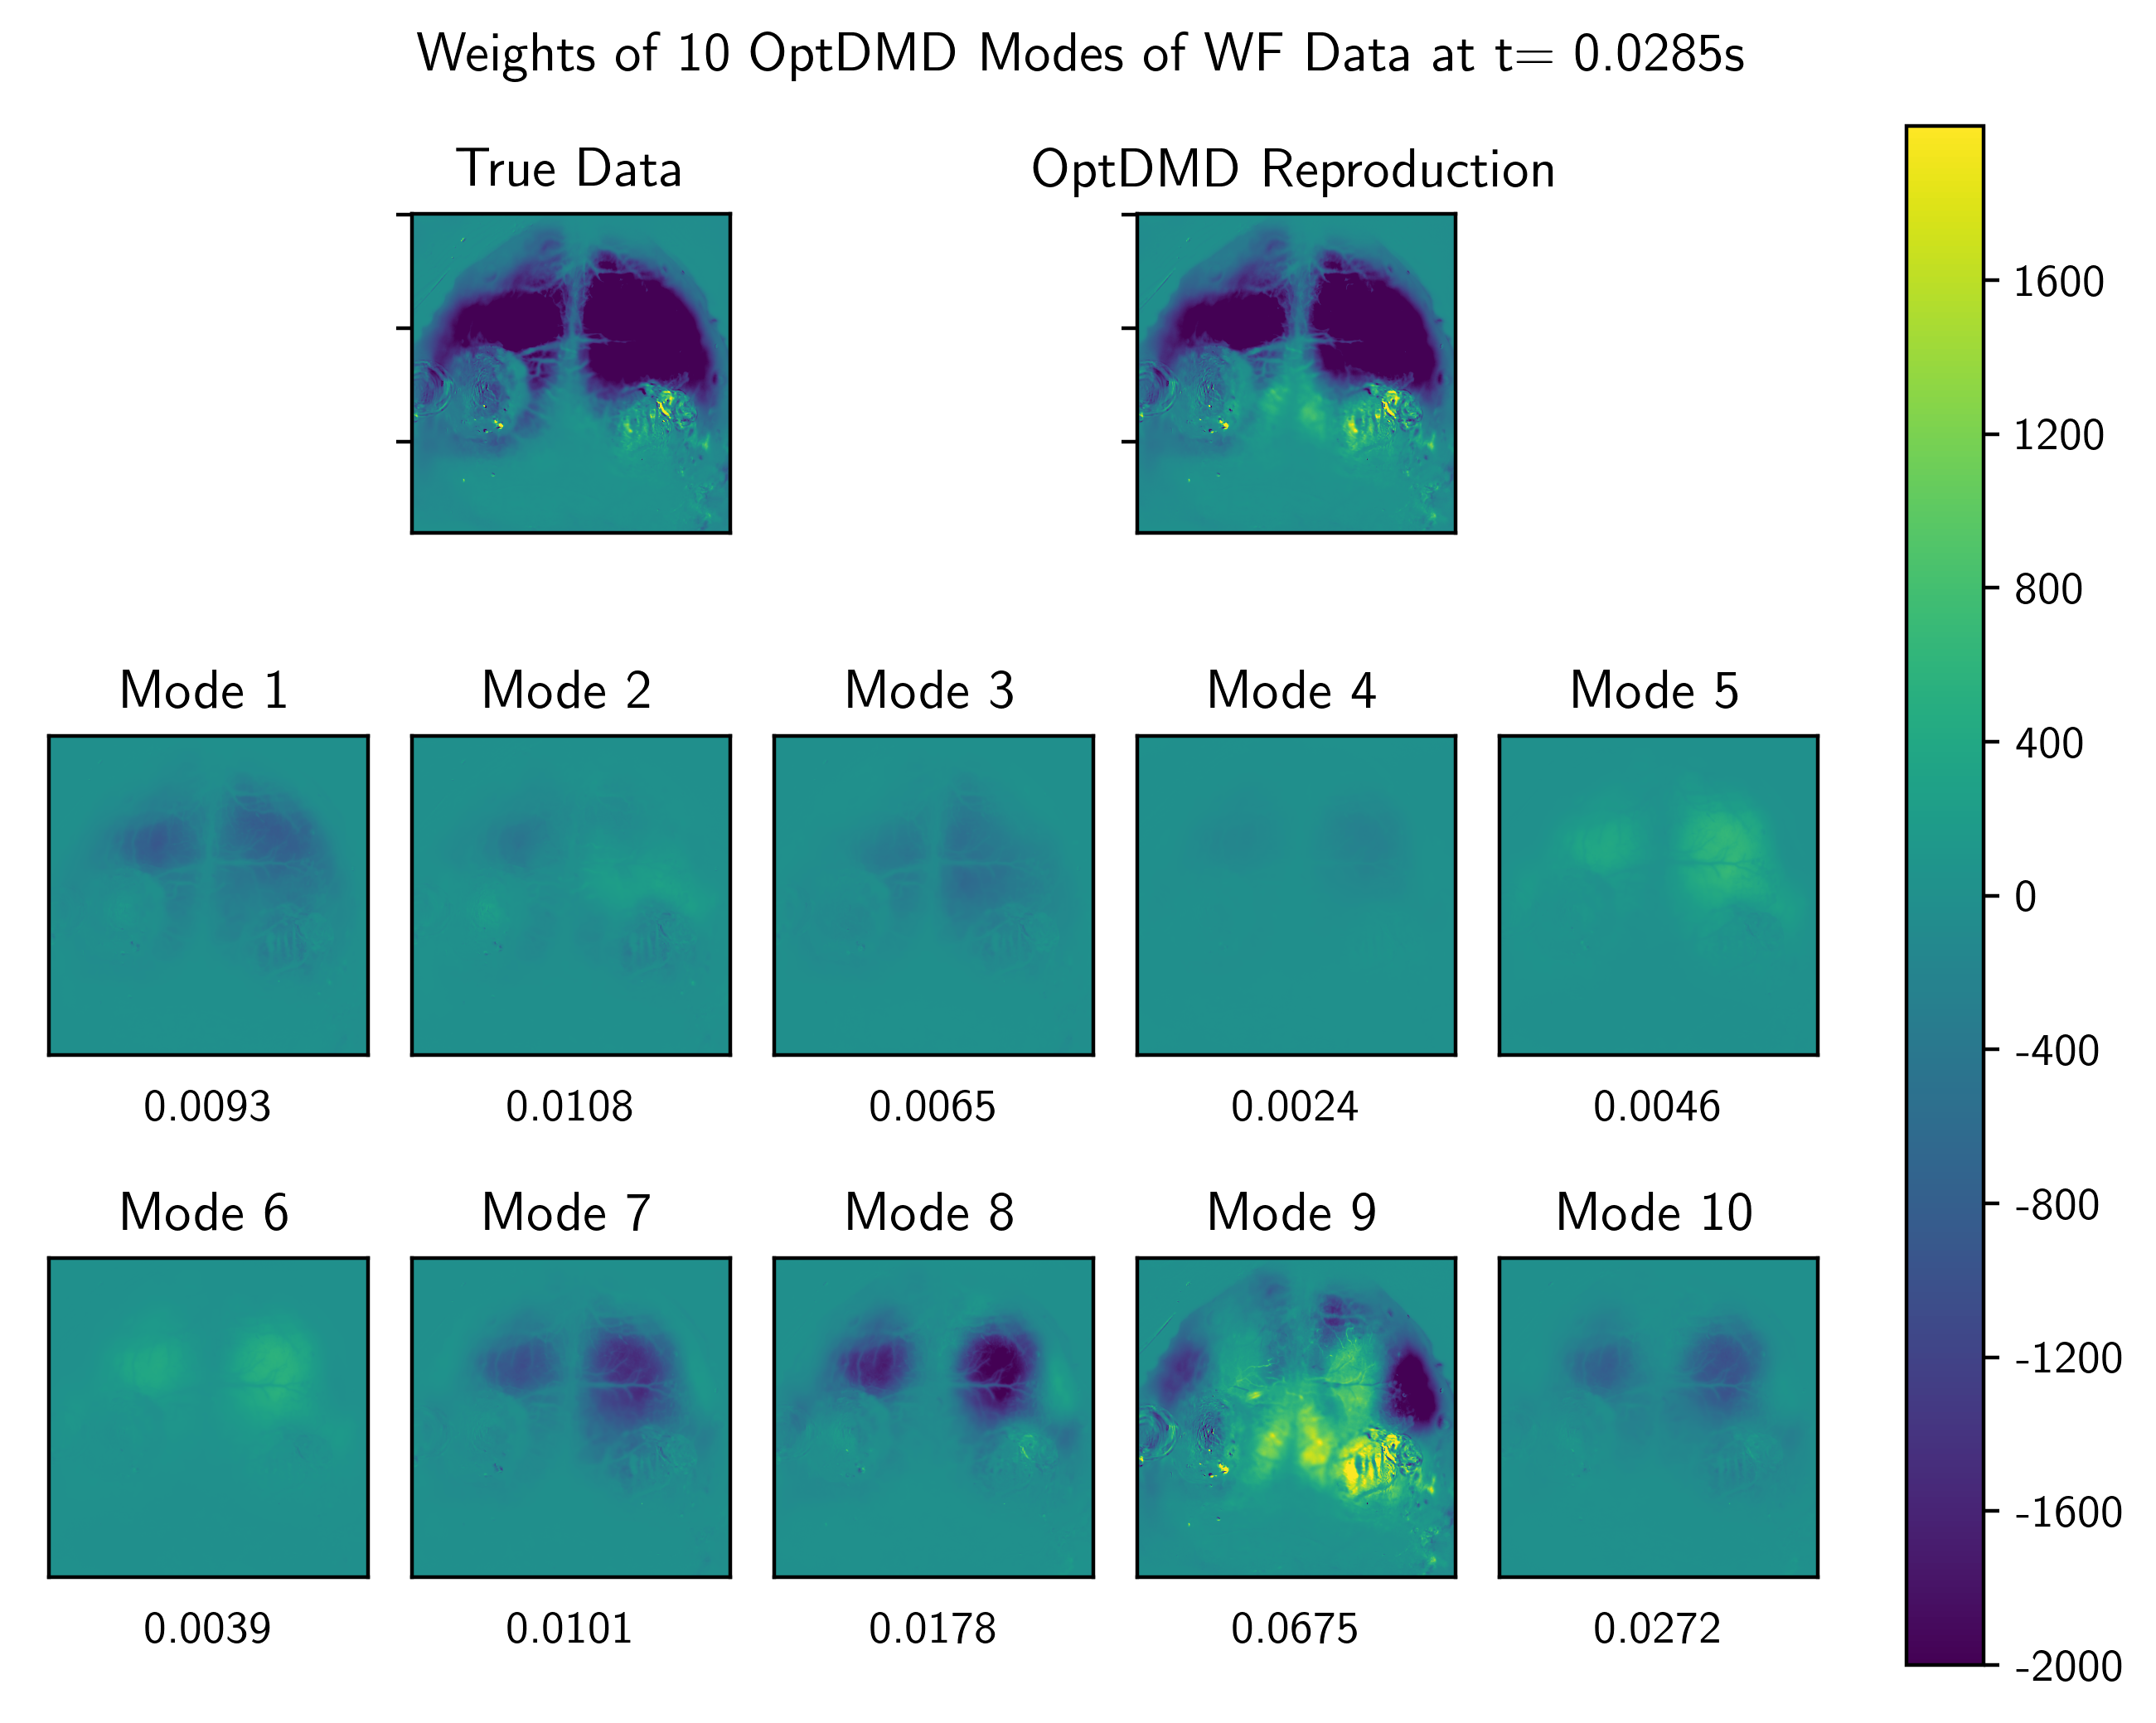

In [49]:
# Import packages for animations
import sys
import warnings
warnings.filterwarnings('ignore')
from matplotlib import animation, rc
rc('animation',html='html5')
# We will create a 3x5 array of plots.
# The top row will be blank except for entry 
fig,ax = plt.subplots(3,5,sharex=True,sharey=True,constrained_layout=True)
ax[0,0].axis('off')
true_ax = ax[0,1].imshow(USV)
ax[0,1].set_title('True Data')
ax[0,2].axis('off')
reproduce_ax = ax[0,3].imshow(np.matmul(top50,np.real(sigma[:50]*optdmd10.reconstructed_data[:,0]),out=matmul_out))
ax[0,3].set_title("OptDMD Reproduction")
ax[0,4].axis('off')
#fig.constrained_layout()
im = []
for i in range(10):
    USV_reconstruct = np.matmul(top50,np.real(sigma[:50]*modes[:,0,i]),out=matmul_out)
    if i < 5:
        im.append(ax[1,i].imshow(USV_reconstruct))
        ax[1,i].set_title("Mode " + str(i+1))
        ax[1,i].get_yaxis().set_visible(False)
        ax[1,i].set_xlabel(np.round(np.real(optdmd10.amplitudes[i]),4))
    else:
        im.append(ax[2,i-5].imshow(USV_reconstruct))
        ax[2,i-5].set_title("Mode " + str(i+1))
        ax[2,i-5].get_yaxis().set_visible(False)
        ax[2,i-5].set_xlabel(np.round(np.real(optdmd10.amplitudes[i]),4))
        ax[2,i-5].set_xticks([])
    del USV_reconstruct
dt = 0.0285
fig.suptitle("Weights of 10 OptDMD Modes of WF Data at t= " + str(0*dt)+"s",y=1.05)
fig.colorbar(true_ax,ax=ax,ticks=np.arange(-2000,2000,400),format="%d")
plt.subplots_adjust(bottom=0.001, top=0.9, hspace=0)
def animate(t):
    print("At iteration " + str(t))
    # True data
    USV = np.matmul(top50,sigma[:50]*V[:50,2*t+1],out=matmul_out)
    true_ax.set_data(USV)
    true_ax.set_clim(np.min(-2000),np.max(2000))
    fig.suptitle("Weights of 10 OptDMD Modes of WF Data at t= " + str(np.round((2*t+1)*dt,7))+"s",y=1.05)
    # Reproduction
    USV = np.matmul(top50,np.real(sigma[:50]*optdmd10.reconstructed_data[:50,2*t+1]),out=matmul_out)
    reproduce_ax.set_data(USV)
    reproduce_ax.set_clim(-2000,2000)
    for i in range(10):
        # Individual modes
        USV = np.matmul(top50,np.real(sigma[:50]*modes[:,2*t+1,i]),out=matmul_out)
        im[i].set_data(USV)
        im[i].set_clim(-2000,2000)
anim = animation.FuncAnimation(fig,animate,frames=249,save_count=None,repeat=False)
writermp4=animation.FFMpegWriter(fps=6)
anim.save('OptDMD Modes Colorbar Scaled.mp4',writer = writermp4)

Aditya discovered that stacking the widefield and time-averaged neuropixel data resulted in a better reconstruction with a subspace system identification method. Let's explore if the same works with OptDMD. Let $V\in\mathbb{R}^{50\times 500}$ be the first $50$ modes and first $500$ timepoints of the WF temporal component data and $N\in\mathbb{R}^{50\times 500}$ be the first $50$ PCA components and 500 time points of the time-averaged neuropixel data. We will compare the RSE in the reconstruction of V from a fit of $\begin{bmatrix} V \\ N \end{bmatrix}$ with the RSE in the reconstruction of $V$ from a fit of $V$, and do the same comparison from a fit of the joint data with a fit of just $N$.

In [79]:
# Create firing rates (sliding time-averaged neuropixel data)
neuropixeldata   = np.load("spikes_v1_clean.npy").T
num_times        = neuropixeldata.shape[0]
num_bins         = num_times-35 # Create bins of width 35
rates            = np.zeros((num_bins,336))
for i in np.arange(num_bins):
    rates[i]     = np.sum(neuropixeldata[i:i+35,:],axis=0)/35 # Average over sliding time window
rates = (rates.T-np.mean(rates,axis=1)).T
# Do PCA
pca = PCA(n_components=50)
pca.fit(rates.T)

We will compute the RSE for the two fits with $24$ modes over each $500$ element data set from $t=0$ to $t=5000$ (timepoints). Then we will average each RSE to hopefully get an idea of whether adding neuropixel data reduces error. The point of doing it this way is that the OptDMD algorithm is deterministic, so we can't say for sure whether a difference in RSEs in one sample is due to our fit being better or variance in our data. But as we add more samples, the variance in our data should decrease.

In [145]:
errors_V    = np.zeros(10)
errors_N    = np.zeros(10)
errors_VN_V = np.zeros(10)
errors_VN_N = np.zeros(10)
for i in tqdm(range(10)):
    N = pca.components_[:,i*500:(i+1)*500]
    # Stack V and N
    VN = np.vstack([V[:50,i*500:(i+1)*500],N])
    # Fit optDMD
    optdmdV = BOPDMD(svd_rank=24)
    optdmdV.fit(V[:50,i*500:(i+1)*500],np.arange(500))
    optdmdN = BOPDMD(svd_rank=24)
    optdmdN.fit(N,np.arange(500))
    optdmdVN = BOPDMD(svd_rank=24)
    optdmdVN.fit(VN,np.arange(500))
    # Compute errors
    errors_V[i]  = RSE(optdmdV.reconstructed_data,V[:50,i*500:(i+1)*500])
    errors_N[i]  = RSE(optdmdN.reconstructed_data,N)
    errors_VN_V[i] = RSE(optdmdVN.reconstructed_data[:50,:],V[:50,i*500:(i+1)*500])
    errors_VN_N[i] = RSE(optdmdVN.reconstructed_data[50:,:],N)

100%|███████████████████████████████████████████| 10/10 [00:11<00:00,  1.12s/it]


In [146]:
print("WF Fit WF Error: " + str(np.round(np.mean(errors_V),5)) + "+-"+ str(np.round(np.std(errors_V)/np.sqrt(10),5)))
print("NP Fit NP Error: " + str(np.round(np.mean(errors_N),5)) + "+-"+ str(np.round(np.std(errors_N)/np.sqrt(10),5)))
print("WF+NP Fit WF Error: " + str(np.round(np.mean(errors_VN_V),5)) + "+-"+ str(np.round(np.std(errors_VN_V/np.sqrt(10)),5)))
print("WF+NP Fit NP Error: " + str(np.round(np.mean(errors_VN_N),5)) + "+-"+ str(np.round(np.std(errors_VN_N/np.sqrt(10)),5)))

WF Fit WF Error: 0.05609+-0.00246
NP Fit NP Error: 0.02046+-0.00218
WF+NP Fit WF Error: 0.0567+-0.00262
WF+NP Fit NP Error: 0.02043+-0.00178


Unfortunately, adding the neuropixel data appears to have slightly increased the error in the widefield case (although the effect is basically negligible, about 1%), and had no significant effect on the error in the neuropixel case. While this is disappointing, the upside is that we are learning a single set of eigenvalues $\lambda_j$ and amplitudes $b_j$ that can be used in a reconstruction of each dataset that is essentially as good as the reconstructions obtained from a fit of just one dataset. (The same cannot be said for the modes, which each consist of 100 entries, the first 50 of which pertain to the widefield data, and the last 50 of which pertain to the neuropixel data). Perhaps the modes found with this method would do better in neuronal regression.